In [63]:
import sys 
sys.path.append("../")
import os
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress
import pymk as pymk #mine
import utils
import matplotlib.dates as mdates
import datetime
from shapely.geometry import Polygon, Point, box
from shapely.ops import unary_union
import matplotlib.gridspec as gridspec
import cartopy.crs as ccrs
from matplotlib.colors import TwoSlopeNorm, BoundaryNorm
import cartopy.feature as cfeature
import gsw

In [2]:
bathy_alb = xr.open_dataset('../../data/006_004_medmfc_bathy_alb.nc')
hflux_alb = xr.open_dataset('../../data/006_004_medmfc_hflux_alb.nc')
mflux_alb = xr.open_dataset('../../data/006_004_medmfc_mflux_alb.nc')
mld_alb = xr.open_dataset('../../data/006_004_medmfc_mld_alb.nc')
so_alb = xr.open_dataset('../../data/006_004_medmfc_so_alb.nc')
ssh_alb = xr.open_dataset('../../data/006_004_medmfc_ssh_alb.nc')
thetao_alb = xr.open_dataset('../../data/006_004_medmfc_thetao_alb.nc')
uovo_alb = xr.open_dataset('../../data/006_004_medmfc_uovo_alb.nc')

bathy_iera = xr.open_dataset('../../data/006_004_medmfc_bathy_iera.nc')
hflux_iera = xr.open_dataset('../../data/006_004_medmfc_hflux_iera.nc')
mflux_iera = xr.open_dataset('../../data/006_004_medmfc_mflux_iera.nc')
mld_iera = xr.open_dataset('../../data/006_004_medmfc_mld_iera.nc')
so_iera = xr.open_dataset('../../data/006_004_medmfc_so_iera.nc')
ssh_iera = xr.open_dataset('../../data/006_004_medmfc_ssh_iera.nc')
thetao_iera = xr.open_dataset('../../data/006_004_medmfc_thetao_iera.nc')
uovo_iera = xr.open_dataset('../../data/006_004_medmfc_uovo_iera.nc')
#Car je n'ai pas pu enregistré uovo_iera2, l'ordi plante
# valid_depth = bathy_iera.mask.any(dim=["latitude", "longitude"])
# bathy_iera = bathy_iera.sel(depth=valid_depth)
# uovo_iera = uovo_iera.sel(depth=valid_depth)

In [ ]:
#to delete unuseful depth levels
# valid_depth = bathy_alb.mask.any(dim=["latitude", "longitude"])
# bathy_alb = bathy_alb.sel(depth=valid_depth)
# so_alb = so_alb.sel(depth=valid_depth)
# thetao_alb = thetao_alb.sel(depth=valid_depth)
# uovo_alb = uovo_alb.sel(depth=valid_depth)

# bathy_alb.to_netcdf('../../data/006_004_medmfc_bathy_alb2.nc')
# so_alb.to_netcdf('../../data/006_004_medmfc_so_alb2.nc')
# thetao_alb.to_netcdf('../../data/006_004_medmfc_thetao_alb2.nc')
# uovo_alb.to_netcdf('../../data/006_004_medmfc_uovo_alb2.nc')



# valid_depth = bathy_iera.mask.any(dim=["latitude", "longitude"])
# so_iera = so_iera.sel(depth=valid_depth)
# thetao_iera = thetao_iera.sel(depth=valid_depth)

# so_iera.to_netcdf('../../data/006_004_medmfc_so_iera2.nc')
# thetao_iera.to_netcdf('../../data/006_004_medmfc_thetao_iera2.nc')

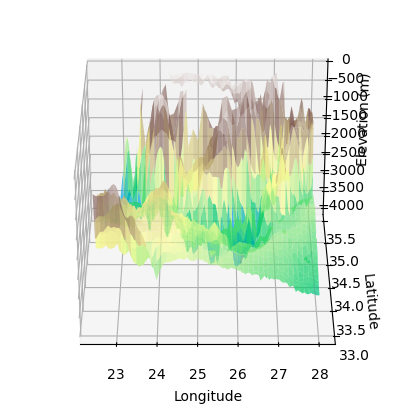

In [ ]:
#plot bathymetry
lon = bathy_iera['longitude'].values
lat = bathy_iera['latitude'].values
elev = -bathy_iera['deptho'].values
Lon, Lat = np.meshgrid(lon, lat)
fig = plt.figure(figsize=(5,5))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(Lon, Lat, elev, cmap='terrain', alpha=0.7)
ax.view_init(elev=30, azim=270)
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_zlabel('Elevation (m)')
plt.show()


In [6]:
def pmk_test(ts):
    if np.isnan(ts).all():
        return np.nan, np.nan, np.nan, np.nan
    results = pymk.yue_wang_modification_test(ts)
    slope, p_value, n_ns, intercept = results.slope, results.p, results.n_ns, results.intercept
    return slope, p_value, n_ns, intercept

def std_mktrend(tseries, slope, intercept, ESS):
    x = np.arange(len(tseries))
    y_pred = (slope/365) * x + intercept
    residuals = tseries - y_pred
    std = 365*np.sqrt(np.sum(residuals**2) / (ESS - 2)) / np.sqrt(np.sum((x - np.mean(x))**2))
    return std

# Compare model/sat

In [3]:
# Mask ISOEKE IERA
# ============================================================
# 1. CONSTRUIRE LE POLYGONE IERAPETRA DEPUIS LE MASQUE EKE
# ============================================================

mask = np.load('../../../Med_Global_EKE/results/masks/2mask_IERAISO_MED.npy', allow_pickle=True)
ekem = xr.open_dataset('../../../Med_Global_EKE/processed_data/MED/ALL_SAT/NEKE_ALL_SAT_MED_C3S_vDT2021_19930101_20230607.nc')
meanekem = ekem.mean(dim='time', skipna=False)

lon = meanekem['lon'].values
lat = meanekem['lat'].values

# Résolution de la grille EKE
dlon = np.abs(np.diff(lon).mean())
dlat = np.abs(np.diff(lat).mean())
half_dlon = dlon / 2
half_dlat = dlat / 2

# ============================================================
# 2. CONSTRUIRE LES CELLULES DU MASQUE
# ============================================================

cells = []
for j, lat0 in enumerate(lat):
    for i, lon0 in enumerate(lon):

        if mask[j, i]:

            cell = box(
                lon0 - half_dlon,
                lat0 - half_dlat,
                lon0 + half_dlon,
                lat0 + half_dlat
            )
            cells.append(cell)
# Fusionner toutes les cellules
polygon_iera = unary_union(cells)

# ============================================================
# 3. PRENDRE UNIQUEMENT LA SURFACE DE UOVO
# ============================================================

uovo_surface = uovo_iera.isel(depth=0)

# ============================================================
# 4. RESOLUTION DE LA GRILLE UOVO
# ============================================================

lat_uovo = uovo_surface["latitude"].values
lon_uovo = uovo_surface["longitude"].values
dlon_uovo = np.abs(np.diff(lon_uovo).mean())
dlat_uovo = np.abs(np.diff(lat_uovo).mean())
half_dlon_uovo = dlon_uovo / 2
half_dlat_uovo = dlat_uovo / 2

# ============================================================
# 5. CONSTRUIRE LE MASQUE À LA RESOLUTION DE UOVO
# ============================================================

mask_uovo = np.zeros((len(lat_uovo), len(lon_uovo)), dtype=bool)
for j, lat0 in enumerate(lat_uovo):
    for i, lon0 in enumerate(lon_uovo):
        cell = box(
            lon0 - half_dlon_uovo,
            lat0 - half_dlat_uovo,
            lon0 + half_dlon_uovo,
            lat0 + half_dlat_uovo
        )
        if cell.intersects(polygon_iera):
            mask_uovo[j, i] = True

# ============================================================
# 6. CONVERTIR LE MASQUE EN XARRAY
# ============================================================

mask_uovo = xr.DataArray(
    mask_uovo,
    coords={"latitude": uovo_surface["latitude"], "longitude": uovo_surface["longitude"]},
    dims=("latitude", "longitude"),
    name="mask_iera")

## Vitesse totale modele

In [4]:
uovo_iera_masked = uovo_surface.where(mask_uovo)

In [5]:
uo_surf = uovo_iera_masked.uo.sel(time=slice(None, '2023-06-07'))
vo_surf = uovo_iera_masked.vo.sel(time=slice(None, '2023-06-07'))
uoa_surf = uo_surf - uo_surf.mean(dim='time')
voa_surf = vo_surf - vo_surf.mean(dim='time')
eke_surf_iera = 0.5 * (uoa_surf**2 + voa_surf**2)*10000

uo_surf = uovo_alb.uo[:,0,:,:].sel(time=slice(None, '2023-06-07'))
vo_surf = uovo_alb.vo[:,0,:,:].sel(time=slice(None, '2023-06-07'))
uoa_surf = uo_surf - uo_surf.mean(dim='time')
voa_surf = vo_surf - vo_surf.mean(dim='time')
eke_surf_alb = 0.5 * (uoa_surf**2 + voa_surf**2)*10000


area = utils.get_area_haversine(eke_surf_iera['latitude'], eke_surf_iera['longitude'])
da_area = xr.Dataset(coords={'latitude': eke_surf_iera.latitude, 'longitude': eke_surf_iera.longitude})
da_area['area'] = (('latitude', 'longitude'), area)
area = da_area['area'].where(eke_surf_iera.notnull().any(dim='time'))
area_sum = area.sum(['latitude', 'longitude']).compute()
area_rat = area/area_sum
ds_meanekesurf_iera = (eke_surf_iera * area_rat).sum(['latitude', 'longitude']).compute()

area = utils.get_area_haversine(eke_surf_alb['latitude'], eke_surf_alb['longitude'])
da_area = xr.Dataset(coords={'latitude': eke_surf_alb.latitude, 'longitude': eke_surf_alb.longitude})
da_area['area'] = (('latitude', 'longitude'), area)
area = da_area['area'].where(eke_surf_alb.notnull().any(dim='time'))
area_sum = area.sum(['latitude', 'longitude']).compute()
area_rat = area/area_sum
ds_meanekesurf_alb = (eke_surf_alb * area_rat).sum(['latitude', 'longitude']).compute()


In [9]:
sliera, piera, nnsiera, interiera = pmk_test(ds_meanekesurf_iera)*np.array((365,1,1,1))
incertiera = std_mktrend(ds_meanekesurf_iera, sliera, interiera, len(ds_meanekesurf_iera)/nnsiera)

slalb, palb, nnsalb, interalb = pmk_test(ds_meanekesurf_alb)*np.array((365,1,1,1))
incertalb = std_mktrend(ds_meanekesurf_alb, slalb, interalb, len(ds_meanekesurf_alb)/nnsalb)

In [7]:
# Satellites
ekem = xr.open_dataset('../../../Med_Global_EKE/processed_data/MED/ALL_SAT/NEKE_ALL_SAT_MED_C3S_vDT2021_19930101_20230607.nc')
ekea = xr.open_dataset('../../../Med_Global_EKE/processed_data/GLO/ALL_SAT/NEKE_ALL_SAT_GLO_C3S_vDT2021_19930101_20230607.nc')
eket = xr.open_dataset('../../../Med_Global_EKE/processed_data/GLO/TWO_SAT/NEKE_TWO_SAT_GLO_C3S_vDT2021_19930101_20230607.nc')
#
maskalbm = np.load('../../../Med_Global_EKE/results/masks/2mask_ALB_MED.npy', allow_pickle=True)
maskalbg = np.load('../../../Med_Global_EKE/results/masks/2mask_ALB_GLO.npy', allow_pickle=True)
ekem_alb = ekem.where(maskalbm)
ekea_alb = ekea.where(maskalbg)
eket_alb = eket.where(maskalbg)
maskierabm = np.load('../../../Med_Global_EKE/results/masks/2mask_IERAISO_MED.npy', allow_pickle=True)
maskierabg = np.load('../../../Med_Global_EKE/results/masks/2mask_IERAISO_GLO.npy', allow_pickle=True)
ekem_ierab = ekem.where(maskierabm)
ekea_ierab = ekea.where(maskierabg)
eket_ierab = eket.where(maskierabg)
#
area = utils.get_area_haversine(ekem_alb['lat'], ekem_alb['lon'])
da_area = xr.Dataset(coords={'lat': ekem_alb.lat, 'lon': ekem_alb.lon})
da_area['area'] = (('lat', 'lon'), area)
area = da_area['area'].where(ekem_alb.EKE.notnull().any(dim='time'))
area_sum = area.sum(['lat', 'lon']).compute()
area_rat = area/area_sum
dsm_alb = (ekem_alb * area_rat).sum(['lat', 'lon']).compute()

area = utils.get_area_haversine(ekea_alb['lat'], ekea_alb['lon'])
da_area = xr.Dataset(coords={'lat': ekea_alb.lat, 'lon': ekea_alb.lon})
da_area['area'] = (('lat', 'lon'), area)
area = da_area['area'].where(ekea_alb.EKE.notnull().any(dim='time'))
area_sum = area.sum(['lat', 'lon']).compute()
area_rat = area/area_sum
dsa_alb = (ekea_alb * area_rat).sum(['lat', 'lon']).compute()
dst_alb = (eket_alb * area_rat).sum(['lat', 'lon']).compute()


area = utils.get_area_haversine(ekem_ierab['lat'], ekem_ierab['lon'])
da_area = xr.Dataset(coords={'lat': ekem_ierab.lat, 'lon': ekem_ierab.lon})
da_area['area'] = (('lat', 'lon'), area)
area = da_area['area'].where(ekem_ierab.EKE.notnull().any(dim='time'))
area_sum = area.sum(['lat', 'lon']).compute()
area_rat = area/area_sum
dsm_ierab = (ekem_ierab * area_rat).sum(['lat', 'lon']).compute()

area = utils.get_area_haversine(ekea_ierab['lat'], ekea_ierab['lon'])
da_area = xr.Dataset(coords={'lat': ekea_ierab.lat, 'lon': ekea_ierab.lon})
da_area['area'] = (('lat', 'lon'), area)
area = da_area['area'].where(ekea_ierab.EKE.notnull().any(dim='time'))
area_sum = area.sum(['lat', 'lon']).compute()
area_rat = area/area_sum
dsa_ierab = (ekea_ierab * area_rat).sum(['lat', 'lon']).compute()
dst_ierab = (eket_ierab * area_rat).sum(['lat', 'lon']).compute()
#
sla_alb, pa_alb, nnsa_alb, intera_alb = pmk_test(dsa_alb.EKE)*np.array((365,1,1,1))
slt_alb, pt_alb, nnst_alb, intert_alb = pmk_test(dst_alb.EKE)*np.array((365,1,1,1))
slm_alb, pm_alb, nnsm_alb, interm_alb = pmk_test(dsm_alb.EKE)*np.array((365,1,1,1))

sla_ierab, pa_ierab, nnsa_ierab, intera_ierab = pmk_test(dsa_ierab.EKE)*np.array((365,1,1,1))
slt_ierab, pt_ierab, nnst_ierab, intert_ierab = pmk_test(dst_ierab.EKE)*np.array((365,1,1,1))
slm_ierab, pm_ierab, nnsm_ierab, interm_ierab = pmk_test(dsm_ierab.EKE)*np.array((365,1,1,1))
#
lenlen = len(dsm_alb.EKE.values)
incertm_ierab = std_mktrend(dsm_ierab.EKE.values, slm_ierab, interm_ierab, lenlen/nnsm_ierab)
incertm_alb = std_mktrend(dsm_alb.EKE.values, slm_alb, interm_alb, lenlen/nnsm_alb)
incerta_ierab = std_mktrend(dsa_ierab.EKE.values, sla_ierab, intera_ierab, lenlen/nnsa_ierab)
incerta_alb = std_mktrend(dsa_alb.EKE.values, sla_alb, intera_alb, lenlen/nnsa_alb)
incertt_ierab = std_mktrend(dst_ierab.EKE.values, slt_ierab, intert_ierab, lenlen/nnst_ierab)
incertt_alb = std_mktrend(dst_alb.EKE.values, slt_alb, intert_alb, lenlen/nnst_alb)

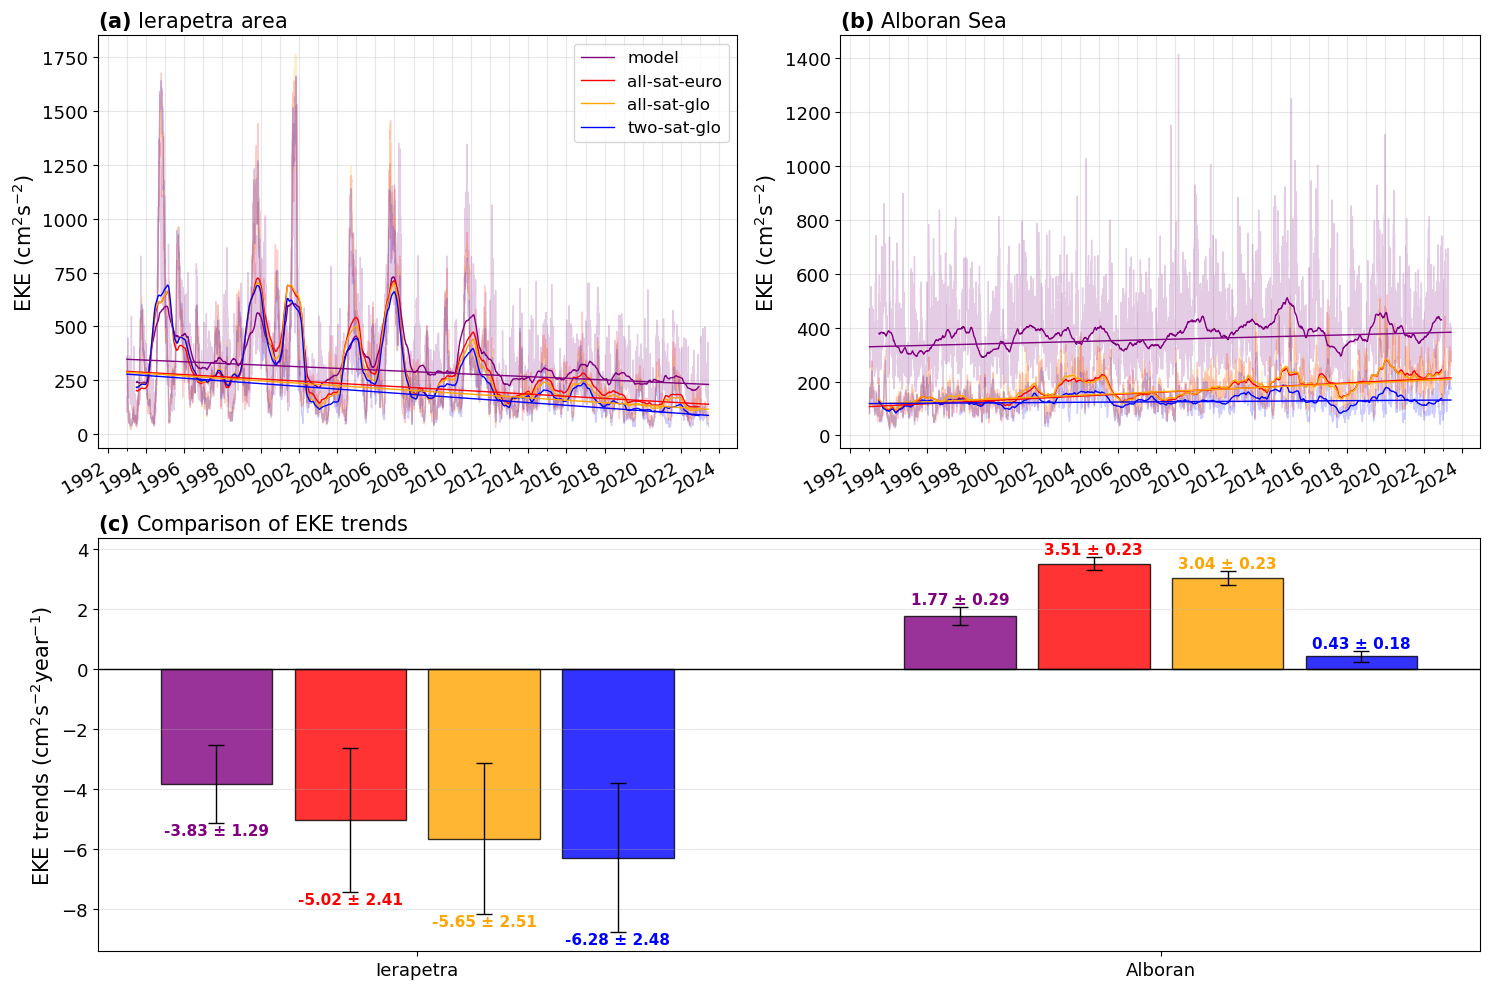

In [10]:
fig = plt.figure(figsize=(15, 10))

gs = gridspec.GridSpec(
    2, 2,
    height_ratios=[1, 1],
    width_ratios=[1, 1],
    figure=fig
)

ax1 = fig.add_subplot(gs[0, 0])   # Ierapetra
ax2 = fig.add_subplot(gs[0, 1])   # Alboran
ax3 = fig.add_subplot(gs[1, :])   # Trends


# ============================================================
# (a) IERAPETRA
# ============================================================

ax1.plot(ds_meanekesurf_iera.time, ds_meanekesurf_iera, color='purple', lw=1, alpha=0.2)
ax1.plot(dsm_ierab.time, dsm_ierab.EKE, color='red', lw=1, alpha=0.2)
ax1.plot(dsa_ierab.time, dsa_ierab.EKE, color='orange', lw=1, alpha=0.2)
ax1.plot(dst_ierab.time, dst_ierab.EKE, color='blue', lw=1, alpha=0.2)
# Moyenne glissante 1 an
ax1.plot(ds_meanekesurf_iera.time, ds_meanekesurf_iera.rolling(time=365, center=True).mean(), color='purple', lw=1)
ax1.plot(dsm_ierab.time, dsm_ierab.EKE.rolling(time=365, center=True).mean(), color='red', lw=1, alpha=1)
ax1.plot(dsa_ierab.time, dsa_ierab.EKE.rolling(time=365, center=True).mean(), color='orange', lw=1, alpha=1)
ax1.plot(dst_ierab.time, dst_ierab.EKE.rolling(time=365, center=True).mean(), color='blue', lw=1, alpha=1)
# Tendance
time_r = ((ds_meanekesurf_iera.time.values - ds_meanekesurf_iera.time.values[0]) / np.timedelta64(1, 'D'))
ax1.plot(ds_meanekesurf_iera.time, sliera / 365 * time_r + interiera,color='purple', linewidth=1, label='model'
        # label=(r'$\beta$ = ' + f'{sliera:.2f}' + r' $\pm$ ' + f'{incertiera:.2f}' + r' cm$^2$s$^{-2}$year$^{-1}$')
        )
time_r = ((dsm_ierab.time.values - dsm_ierab.time.values[0]) / np.timedelta64(1, 'D'))
ax1.plot(dsm_ierab.time, slm_ierab/365 * time_r + interm_ierab, color='red', linewidth=1, label='all-sat-euro')
time_r = ((dsa_ierab.time.values - dsa_ierab.time.values[0]) / np.timedelta64(1, 'D'))
ax1.plot(dsa_ierab.time, sla_ierab/365 * time_r + intera_ierab, color='orange', linewidth=1, label='all-sat-glo')
time_r = ((dst_ierab.time.values - dst_ierab.time.values[0]) / np.timedelta64(1, 'D'))
ax1.plot(dst_ierab.time, slt_ierab/365 * time_r + intert_ierab, color='blue', linewidth=1, label='two-sat-glo')

ax1.set_ylabel('EKE (cm$^2$s$^{-2}$)', fontsize=15)
ax1.set_title(r'$\bf{(a)}$ Ierapetra area', fontsize=15, loc='left')
ax1.legend(fontsize=12, loc='upper right')
ax1.grid(True, which='both', axis='both', alpha=0.3)
ax1.xaxis.set_major_locator(mdates.YearLocator(2))
ax1.xaxis.set_minor_locator(mdates.YearLocator(1))
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.setp(ax1.xaxis.get_majorticklabels(), rotation=30, ha='right')

# ============================================================
# (b) ALBORAN
# ============================================================

ax2.plot(ds_meanekesurf_alb.time, ds_meanekesurf_alb, color='purple', lw=1, alpha=0.2)
ax2.plot(dsm_alb.time, dsm_alb.EKE, color='red', lw=1, alpha=0.2)
ax2.plot(dsa_alb.time, dsa_alb.EKE, color='orange', lw=1, alpha=0.2)
ax2.plot(dst_alb.time, dst_alb.EKE, color='blue', lw=1, alpha=0.2)
# Moyenne glissante 1 an
ax2.plot(ds_meanekesurf_alb.time, ds_meanekesurf_alb.rolling(time=365, center=True).mean(), color='purple', lw=1)
ax2.plot(dsm_alb.time, dsm_alb.EKE.rolling(time=365, center=True).mean(), color='red', lw=1, alpha=1)
ax2.plot(dsa_alb.time, dsa_alb.EKE.rolling(time=365, center=True).mean(), color='orange', lw=1, alpha=1)
ax2.plot(dst_alb.time, dst_alb.EKE.rolling(time=365, center=True).mean(), color='blue', lw=1, alpha=1)
# Tendance
time_r = ((ds_meanekesurf_alb.time.values - ds_meanekesurf_alb.time.values[0]) / np.timedelta64(1, 'D'))
ax2.plot(ds_meanekesurf_alb.time, slalb / 365 * time_r + interalb, color='purple', linewidth=1,
        # label=(r'$\beta$ = ' + f'{slalb:.2f}' + r' $\pm$ ' + f'{incertalb:.2f}' + r' cm$^2$s$^{-2}$year$^{-1}$')
        )
time_r = ((dsm_alb.time.values - dsm_alb.time.values[0]) / np.timedelta64(1, 'D'))
ax2.plot(dsm_alb.time, slm_alb/365 * time_r + interm_alb, color='red', linewidth=1)
time_r = ((dsa_alb.time.values - dsa_alb.time.values[0]) / np.timedelta64(1, 'D'))
ax2.plot(dsa_alb.time, sla_alb/365 * time_r + intera_alb, color='orange', linewidth=1)
time_r = ((dst_alb.time.values - dst_alb.time.values[0]) / np.timedelta64(1, 'D'))
ax2.plot(dst_alb.time, slt_alb/365 * time_r + intert_alb, color='blue', linewidth=1)

ax2.set_ylabel('EKE (cm$^2$s$^{-2}$)', fontsize=15)
ax2.set_title(r'$\bf{(b)}$ Alboran Sea', fontsize=15, loc='left')
# ax2.legend(fontsize=12, loc='upper left')
ax2.grid(True, which='both', axis='both', alpha=0.3)
ax2.xaxis.set_major_locator(mdates.YearLocator(2))
ax2.xaxis.set_minor_locator(mdates.YearLocator(1))
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.setp(ax2.xaxis.get_majorticklabels(), rotation=30, ha='right')

# ============================================================
# (c) COMPARAISON DES TENDANCES
# ============================================================

regions = ['Ierapetra', 'Alboran']

slopes_model = [sliera, slalb]
slopes_m = [slm_ierab, slm_alb]
slopes_a = [sla_ierab, sla_alb]
slopes_t = [slt_ierab, slt_alb]

errors_model = [incertiera, incertalb]
errors_m = [incertm_ierab, incertm_alb]
errors_a = [incerta_ierab, incerta_alb]
errors_t = [incertt_ierab, incertt_alb]

pvalues_model = [piera, palb]
pvalues_m = [pm_ierab, pm_alb]
pvalues_a = [pa_ierab, pa_alb]
pvalues_t = [pt_ierab, pt_alb]

xbar = np.arange(len(regions))
offset = 0.18
widthbar = 0.15

color_model = 'purple'
color_m = 'red'
color_a = 'orange'
color_t = 'blue'

all_slopes = [slopes_model, slopes_m, slopes_a, slopes_t]
all_errors = [errors_model, errors_m, errors_a, errors_t]
all_pvalues = [pvalues_model, pvalues_m, pvalues_a, pvalues_t]
all_colors = [color_model, color_m, color_a, color_t]
all_offsets = [-1.5 * offset, -0.5 * offset, 0.5 * offset, 1.5 * offset]

ax3.axhline(0, color='black', linewidth=1)
ax3.set_xticks(xbar)
ax3.set_xticklabels(regions, fontsize=15)
ax3.set_ylabel('EKE trends (cm$^2$s$^{-2}$year$^{-1}$)', fontsize=15)
ax3.set_title(r'$\bf{(c)}$ Comparison of EKE trends', fontsize=15, loc='left')
ax3.grid(True, axis='y', alpha=0.3)
for slopes, errors, pvalues, color, off in zip(all_slopes, all_errors, all_pvalues, all_colors, all_offsets):
    for i, (slope, error, pvalue) in enumerate(zip(slopes, errors, pvalues)):
        if pvalue > 0.05:
                    hatch = '//'
                    fontweight = 'normal'
                    fontstyle = 'italic'
        else:
                    hatch = None
                    fontweight = 'bold'
                    fontstyle = 'normal'
        ax3.bar(xbar[i] + off, slope, widthbar, color=color, alpha=0.8, edgecolor='black', hatch=hatch)
        ax3.errorbar(xbar[i] + off, slope, yerr=error, fmt='none', ecolor='black', elinewidth=1, capsize=6)
        if slope >= 0:
            y = slope + error
            va = 'bottom'
        else:
            y = slope - error
            va = 'top'
        ax3.text(xbar[i] + off, y, f'{slope:.2f} ± {error:.2f}',
            ha='center', va=va, fontsize=11, color=color, fontweight=fontweight, fontstyle=fontstyle)
# ax3.legend(fontsize=12, ncol=4, loc='upper center', bbox_to_anchor=(0.5, 1.02))

# ============================================================
# STYLE
# ============================================================

for ax in [ax1, ax2, ax3]:
    ax.tick_params(axis='both', labelsize=13)
plt.tight_layout()

plt.show()

In [11]:
sl_alb_mod = np.load('../../results/model_alb_slpintns.npy', allow_pickle=True)
sl_alb_mod = sl_alb_mod.item()

sl_iera_mod = np.load('../../results/model_iera_slpintns.npy', allow_pickle=True)
sl_iera_mod = sl_iera_mod.item()

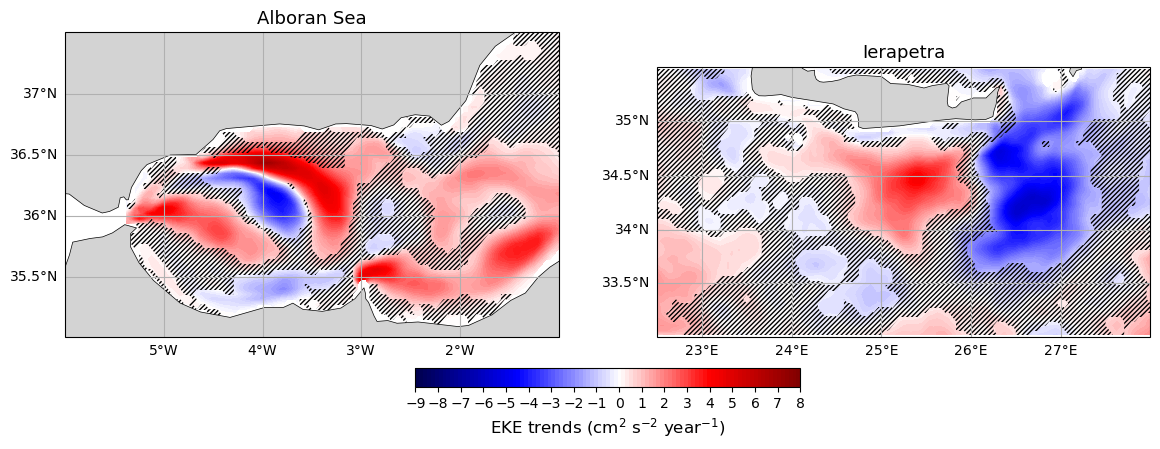

In [17]:
fig = plt.figure(figsize=(14, 5))
ax1 = fig.add_subplot(1, 2, 1, projection=ccrs.Mercator())
ax2 = fig.add_subplot(1, 2, 2, projection=ccrs.Mercator())

# Alboran
lon_min_alb = -6
lon_max_alb = -1
lat_min_alb = 35
lat_max_alb = 37.5

# Ierapetra
lon_min_iera = 22.5
lon_max_iera = 28
lat_min_iera = 33
lat_max_iera = 35.5

ax1.set_extent([lon_min_alb, lon_max_alb, lat_min_alb, lat_max_alb], crs=ccrs.PlateCarree())
ax2.set_extent([lon_min_iera, lon_max_iera, lat_min_iera, lat_max_iera], crs=ccrs.PlateCarree())

for ax in [ax1, ax2]:
    gl = ax.gridlines(draw_labels=True, dms=False, x_inline=False, y_inline=False)
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 10, 'color': 'black'}
    gl.ylabel_style = {'size': 10, 'color': 'black'}

lon_alb = uovo_alb.longitude.values
lat_alb = uovo_alb.latitude.values
lon_iera = uovo_iera.longitude.values
lat_iera = uovo_iera.latitude.values

vmin = -9
vmax = 8
norm = TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax)
levels = np.linspace(vmin, vmax, 100)
contour1 = ax1.contourf(lon_alb, lat_alb, sl_alb_mod['slope'] * 365, 
                        levels=levels, cmap='seismic', norm=norm, transform=ccrs.PlateCarree())
# Significance hatching
mask_alb_mod = np.where(sl_alb_mod['pvalue'] > 0.05, 1, np.nan)
ax1.contourf(lon_alb, lat_alb, mask_alb_mod, 
             levels=[0.99, 1.01], colors='none', hatches=['///////'], transform=ccrs.PlateCarree())


contour2 = ax2.contourf(lon_iera, lat_iera, sl_iera_mod['slope'] * 365,
                        levels=levels, cmap='seismic', norm=norm, transform=ccrs.PlateCarree())
# Significance hatching
mask_iera_mod = np.where(sl_iera_mod['pvalue'] > 0.05, 1, np.nan)
ax2.contourf(lon_iera, lat_iera, mask_iera_mod, levels=[0.99, 1.01],
             colors='none', hatches=['///////'], transform=ccrs.PlateCarree())

ccrs_land = cfeature.NaturalEarthFeature('physical', 'land',
    '50m', edgecolor='black', facecolor='lightgrey', linewidth=0.5)
for ax in [ax1, ax2]:
    ax.add_feature(ccrs_land)

ax1.set_title('Alboran Sea', fontsize=13)
ax2.set_title('Ierapetra', fontsize=13)
cbar = fig.colorbar(contour1, ax=[ax1, ax2], orientation='horizontal', pad=0.08, fraction=0.05)
cbar.set_label(r'EKE trends (cm$^2$ s$^{-2}$ year$^{-1}$)', fontsize=12)
cbar.ax.tick_params(labelsize=10)
cbar.set_ticks(np.arange(vmin, vmax + 1, 1))

plt.show()

## Vitesse geos modele

In [19]:
# Compute vgeo model
# ============================================================
# CONSTANTES
# ============================================================

g = 9.81                  # gravité [m s-2]
Omega = 7.292115e-5       # rotation terrestre [s-1]
R = 6371000.0             # rayon terrestre [m]


# ============================================================
# POIDS DE DIFFERENCES FINIES
# ============================================================

def fd_weights_first_derivative(offsets):
    """
    Calcule les coefficients de différences finies
    pour la première dérivée.

    Parameters
    ----------
    offsets : array-like
        Positions relatives des points par rapport
        au point où la dérivée est calculée.

    Returns
    -------
    weights : ndarray
        Poids de la différence finie.
    """

    offsets = np.asarray(offsets, dtype=float)
    n = len(offsets)

    A = np.vstack([offsets**k for k in range(n)])

    b = np.zeros(n)
    b[1] = 1.0

    weights = np.linalg.solve(A, b)

    return weights


# ============================================================
# DERIVEE AVEC GESTION DES NaN
# ============================================================

def derivative_9point_nan_safe(field, axis, h):
    """
    Première dérivée spatiale avec :

    1. stencil centré 9 points si les 9 valeurs sont valides ;
    2. sinon différence centrée 2 points si possible ;
    3. sinon différence vers la droite si le point de gauche
       est NaN ;
    4. sinon différence vers la gauche si le point de droite
       est NaN ;
    5. NaN si aucun calcul physique n'est possible.

    Parameters
    ----------
    field : ndarray
        Tableau 2D ou 3D.

    axis : int
        Axe selon lequel calculer la dérivée.

    h : float
        Pas spatial.

    Returns
    -------
    derivative : ndarray
        Première dérivée.
    """

    field = np.asarray(field, dtype=np.float64)

    n = field.shape[axis]

    if n < 9:
        raise ValueError(
            "Il faut au moins 9 points dans la dimension considérée."
        )

    # --------------------------------------------------------
    # INITIALISATION
    # --------------------------------------------------------

    derivative = np.full_like(
        field,
        np.nan,
        dtype=np.float64
    )

    # ========================================================
    # POIDS DU STENCIL 9 POINTS
    # ========================================================

    offsets = np.arange(-4, 5)

    weights = fd_weights_first_derivative(offsets)

    # ========================================================
    # DERIVEE 9 POINTS
    # ========================================================

    for i in range(4, n - 4):

        points = np.arange(i - 4, i + 5)

        # ----------------------------------------------------
        # Extraction des 9 points
        # ----------------------------------------------------

        values = np.take(
            field,
            points,
            axis=axis
        )

        # ----------------------------------------------------
        # Vérification :
        # toutes les valeurs du stencil doivent être valides
        # ----------------------------------------------------

        valid_9 = np.all(
            np.isfinite(values),
            axis=axis
        )

        # ----------------------------------------------------
        # Calcul du stencil 9 points
        # ----------------------------------------------------

        result_9 = np.zeros_like(
            np.take(field, i, axis=axis),
            dtype=np.float64
        )

        for point, weight in zip(points, weights):

            result_9 += (
                weight
                * np.take(field, point, axis=axis)
            )

        result_9 /= h

        # ----------------------------------------------------
        # Insertion uniquement lorsque les 9 points sont valides
        # ----------------------------------------------------

        sl = [slice(None)] * field.ndim
        sl[axis] = i

        derivative_i = derivative[tuple(sl)]

        derivative_i[valid_9] = result_9[valid_9]

        derivative[tuple(sl)] = derivative_i

    # ========================================================
    # FALLBACK : DIFFERENCES A 2 POINTS
    # ========================================================

    for i in range(1, n - 1):

        # ----------------------------------------------------
        # Valeur centrale
        # ----------------------------------------------------

        f0 = np.take(
            field,
            i,
            axis=axis
        )

        # ----------------------------------------------------
        # Point gauche
        # ----------------------------------------------------

        f_left = np.take(
            field,
            i - 1,
            axis=axis
        )

        # ----------------------------------------------------
        # Point droit
        # ----------------------------------------------------

        f_right = np.take(
            field,
            i + 1,
            axis=axis
        )

        # ----------------------------------------------------
        # Masques de validité
        # ----------------------------------------------------

        valid_center = np.isfinite(f0)
        valid_left = np.isfinite(f_left)
        valid_right = np.isfinite(f_right)

        # ----------------------------------------------------
        # Calcul centré
        #
        # f'(x) = [f(x+h)-f(x-h)] / 2h
        # ----------------------------------------------------

        valid_centered = (
            valid_center
            & valid_left
            & valid_right
        )

        result = np.full_like(
            f0,
            np.nan,
            dtype=np.float64
        )

        result[valid_centered] = (
            f_right[valid_centered]
            - f_left[valid_centered]
        ) / (2.0 * h)

        # ----------------------------------------------------
        # Si le point gauche est NaN :
        #
        # différence vers la droite
        #
        # f'(x) = [f(x+h)-f(x)] / h
        # ----------------------------------------------------

        valid_right_only = (
            valid_center
            & (~valid_left)
            & valid_right
        )

        result[valid_right_only] = (
            f_right[valid_right_only]
            - f0[valid_right_only]
        ) / h

        # ----------------------------------------------------
        # Si le point droit est NaN :
        #
        # différence vers la gauche
        #
        # f'(x) = [f(x)-f(x-h)] / h
        # ----------------------------------------------------

        valid_left_only = (
            valid_center
            & valid_left
            & (~valid_right)
        )

        result[valid_left_only] = (
            f0[valid_left_only]
            - f_left[valid_left_only]
        ) / h

        # ----------------------------------------------------
        # On remplace uniquement les points qui n'ont pas
        # déjà obtenu une dérivée 9 points
        # ----------------------------------------------------

        sl = [slice(None)] * field.ndim
        sl[axis] = i

        derivative_i = derivative[tuple(sl)]

        fallback = np.isnan(derivative_i)

        derivative_i[fallback] = result[fallback]

        derivative[tuple(sl)] = derivative_i

    # ========================================================
    # PREMIER POINT
    # ========================================================

    f0 = np.take(field, 0, axis=axis)
    f1 = np.take(field, 1, axis=axis)

    result = np.full_like(
        f0,
        np.nan,
        dtype=np.float64
    )

    valid = (
        np.isfinite(f0)
        & np.isfinite(f1)
    )

    # différence avant
    result[valid] = (
        f1[valid] - f0[valid]
    ) / h

    sl = [slice(None)] * field.ndim
    sl[axis] = 0

    derivative[tuple(sl)] = result

    # ========================================================
    # DERNIER POINT
    # ========================================================

    fn2 = np.take(
        field,
        n - 2,
        axis=axis
    )

    fn1 = np.take(
        field,
        n - 1,
        axis=axis
    )

    result = np.full_like(
        fn1,
        np.nan,
        dtype=np.float64
    )

    valid = (
        np.isfinite(fn1)
        & np.isfinite(fn2)
    )

    # différence arrière
    result[valid] = (
        fn1[valid] - fn2[valid]
    ) / h

    sl = [slice(None)] * field.ndim
    sl[axis] = n - 1

    derivative[tuple(sl)] = result

    return derivative


# ============================================================
# CALCUL DES VITESSES GEOSTROPHIQUES
# ============================================================

def compute_geostrophic_velocity(
    zos,
    latitude,
    longitude,
    time_chunk=200
):
    """
    Calcule les vitesses géostrophiques à partir de SSH.

    ug = -g/f * dSSH/dy
    vg =  g/f * dSSH/dx

    La dérivée utilise :
        - 9 points lorsque possible ;
        - 2 points centrés près des NaN ;
        - différence vers la droite/gauche si nécessaire.

    Parameters
    ----------
    zos : xarray.DataArray
        SSH [m], dimensions :
        (time, latitude, longitude)

    latitude : 1D array
        Latitude [degrees].

    longitude : 1D array
        Longitude [degrees].

    time_chunk : int
        Nombre de pas de temps traités simultanément.

    Returns
    -------
    ug : xarray.DataArray
        Vitesse géostrophique zonale [m/s].

    vg : xarray.DataArray
        Vitesse géostrophique méridienne [m/s].
    """

    # ========================================================
    # COORDONNEES
    # ========================================================

    lat = np.asarray(
        latitude,
        dtype=float
    )

    lon = np.asarray(
        longitude,
        dtype=float
    )

    ntime = zos.sizes["time"]
    nlat = zos.sizes["latitude"]
    nlon = zos.sizes["longitude"]

    # ========================================================
    # VERIFICATION DES DIMENSIONS
    # ========================================================

    if zos.dims != (
        "time",
        "latitude",
        "longitude"
    ):
        raise ValueError(
            f"Dimensions inattendues : {zos.dims}. "
            "Attendu : "
            "('time', 'latitude', 'longitude')"
        )

    # ========================================================
    # PAS ANGULAIRES
    # ========================================================

    dlat = np.diff(lat)
    dlon = np.diff(lon)

    dphi = np.deg2rad(
        np.median(dlat)
    )

    dlambda = np.deg2rad(
        np.median(dlon)
    )

    # ========================================================
    # CORIOLIS
    # ========================================================

    phi = np.deg2rad(lat)

    f = (
        2.0
        * Omega
        * np.sin(phi)
    )

    # shape = (latitude, 1)
    f = f[:, None]

    # ========================================================
    # PAS PHYSIQUES
    # ========================================================

    dy = R * dphi

    dx = (
        R
        * np.cos(phi)
        * dlambda
    )

    # ========================================================
    # PREALLOCATION
    # ========================================================

    ug_all = np.empty(
        (ntime, nlat, nlon),
        dtype=np.float32
    )

    vg_all = np.empty(
        (ntime, nlat, nlon),
        dtype=np.float32
    )

    # ========================================================
    # BOUCLE TEMPORELLE
    # ========================================================

    for start in range(
        0,
        ntime,
        time_chunk
    ):

        end = min(
            start + time_chunk,
            ntime
        )

        print(
            f"Calcul géostrophique : "
            f"{start} -> {end} / {ntime}"
        )

        # ----------------------------------------------------
        # CHARGEMENT DU BLOC SSH
        # ----------------------------------------------------

        ssh = zos.isel(
            time=slice(start, end)
        ).values.astype(np.float64)

        # ====================================================
        # dSSH / dLATITUDE
        # ====================================================

        dssh_dphi = derivative_9point_nan_safe(
            ssh,
            axis=1,
            h=dphi
        )

        # ====================================================
        # dSSH / dLONGITUDE
        # ====================================================

        dssh_dlambda = derivative_9point_nan_safe(
            ssh,
            axis=2,
            h=dlambda
        )

        # ====================================================
        # CONVERSION EN DERIVEES PHYSIQUES
        # ====================================================

        # dSSH / dy
        dssh_dy = (
            dssh_dphi / R
        )

        # dSSH / dx
        dssh_dx = (
            dssh_dlambda
            /
            (
                R
                * np.cos(phi)[None, :, None]
            )
        )

        # ====================================================
        # VITESSES GEOSTROPHIQUES
        # ====================================================

        # ug = -g/f * dSSH/dy
        ug = (
            -g
            / f[None, :, :]
            * dssh_dy
        )

        # vg = +g/f * dSSH/dx
        vg = (
            +g
            / f[None, :, :]
            * dssh_dx
        )

        # ====================================================
        # STOCKAGE
        # ====================================================

        ug_all[start:end] = (
            ug.astype(np.float32)
        )

        vg_all[start:end] = (
            vg.astype(np.float32)
        )

    # ========================================================
    # XARRAY
    # ========================================================

    ug = xr.DataArray(
        ug_all,
        dims=(
            "time",
            "latitude",
            "longitude"
        ),
        coords={
            "time": zos.time,
            "latitude": zos.latitude,
            "longitude": zos.longitude
        },
        name="ug"
    )

    vg = xr.DataArray(
        vg_all,
        dims=(
            "time",
            "latitude",
            "longitude"
        ),
        coords={
            "time": zos.time,
            "latitude": zos.latitude,
            "longitude": zos.longitude
        },
        name="vg"
    )

    # ========================================================
    # ATTRIBUTS
    # ========================================================

    ug.attrs["long_name"] = (
        "geostrophic zonal velocity"
    )

    ug.attrs["units"] = "m s-1"

    vg.attrs["long_name"] = (
        "geostrophic meridional velocity"
    )

    vg.attrs["units"] = "m s-1"

    return ug, vg


In [20]:
# ALBORAN
zos = ssh_alb["zos"]
ug_alb, vg_alb = compute_geostrophic_velocity(zos,
    latitude=ssh_alb["latitude"].values,
    longitude=ssh_alb["longitude"].values,
    time_chunk=200)
ds_geo_alb = xr.Dataset({
    "ug": ug_alb,
    "vg": vg_alb})

# IERAPETRA
zos = ssh_iera["zos"]
ug_iera, vg_iera = compute_geostrophic_velocity(zos,
    latitude=ssh_iera["latitude"].values,
    longitude=ssh_iera["longitude"].values,
    time_chunk=200)
ds_geo_iera = xr.Dataset({
    "ug": ug_iera,
    "vg": vg_iera})

# SAUVEGARDE
ds_geo_alb.to_netcdf("../../results/006_004_medmfc_vg_alb.nc")
ds_geo_iera.to_netcdf("../../results/006_004_medmfc_vg_iera.nc")

Calcul géostrophique : 0 -> 200 / 12296
Calcul géostrophique : 200 -> 400 / 12296
Calcul géostrophique : 400 -> 600 / 12296
Calcul géostrophique : 600 -> 800 / 12296
Calcul géostrophique : 800 -> 1000 / 12296
Calcul géostrophique : 1000 -> 1200 / 12296
Calcul géostrophique : 1200 -> 1400 / 12296
Calcul géostrophique : 1400 -> 1600 / 12296
Calcul géostrophique : 1600 -> 1800 / 12296
Calcul géostrophique : 1800 -> 2000 / 12296
Calcul géostrophique : 2000 -> 2200 / 12296
Calcul géostrophique : 2200 -> 2400 / 12296
Calcul géostrophique : 2400 -> 2600 / 12296
Calcul géostrophique : 2600 -> 2800 / 12296
Calcul géostrophique : 2800 -> 3000 / 12296
Calcul géostrophique : 3000 -> 3200 / 12296
Calcul géostrophique : 3200 -> 3400 / 12296
Calcul géostrophique : 3400 -> 3600 / 12296
Calcul géostrophique : 3600 -> 3800 / 12296
Calcul géostrophique : 3800 -> 4000 / 12296
Calcul géostrophique : 4000 -> 4200 / 12296
Calcul géostrophique : 4200 -> 4400 / 12296
Calcul géostrophique : 4400 -> 4600 / 12296

In [21]:
ds_geo_alb = xr.open_dataset('../../results/006_004_medmfc_vg_alb.nc')
ds_geo_iera = xr.open_dataset('../../results/006_004_medmfc_vg_iera.nc')

ds_geo_iera = ds_geo_iera.where(mask_uovo)

In [22]:
ug_surf = ds_geo_iera.ug.sel(time=slice(None, '2023-06-07'))
vg_surf = ds_geo_iera.vg.sel(time=slice(None, '2023-06-07'))
uga_surf = ug_surf - ug_surf.mean(dim='time')
vga_surf = vg_surf - vg_surf.mean(dim='time')
ekeg_surf_iera = 0.5 * (uga_surf**2 + vga_surf**2)*10000

ug_surf = ds_geo_alb.ug.sel(time=slice(None, '2023-06-07'))
vg_surf = ds_geo_alb.vg.sel(time=slice(None, '2023-06-07'))
uga_surf = ug_surf - ug_surf.mean(dim='time')
vga_surf = vg_surf - vg_surf.mean(dim='time')
ekeg_surf_alb = 0.5 * (uga_surf**2 + vga_surf**2)*10000


area = utils.get_area_haversine(ekeg_surf_iera['latitude'], ekeg_surf_iera['longitude'])
da_area = xr.Dataset(coords={'latitude': ekeg_surf_iera.latitude, 'longitude': ekeg_surf_iera.longitude})
da_area['area'] = (('latitude', 'longitude'), area)
area = da_area['area'].where(ekeg_surf_iera.notnull().any(dim='time'))
area_sum = area.sum(['latitude', 'longitude']).compute()
area_rat = area/area_sum
ds_meanekegsurf_iera = (ekeg_surf_iera * area_rat).sum(['latitude', 'longitude']).compute()

area = utils.get_area_haversine(ekeg_surf_alb['latitude'], ekeg_surf_alb['longitude'])
da_area = xr.Dataset(coords={'latitude': ekeg_surf_alb.latitude, 'longitude': ekeg_surf_alb.longitude})
da_area['area'] = (('latitude', 'longitude'), area)
area = da_area['area'].where(ekeg_surf_alb.notnull().any(dim='time'))
area_sum = area.sum(['latitude', 'longitude']).compute()
area_rat = area/area_sum
ds_meanekegsurf_alb = (ekeg_surf_alb * area_rat).sum(['latitude', 'longitude']).compute()

In [23]:
slierag, pierag, nnsierag, interierag = pmk_test(ds_meanekegsurf_iera)*np.array((365,1,1,1))
incertierag = std_mktrend(ds_meanekegsurf_iera, slierag, interierag, len(ds_meanekegsurf_iera)/nnsierag)

slalbg, palbg, nnsalbg, interalbg = pmk_test(ds_meanekegsurf_alb)*np.array((365,1,1,1))
incertalbg = std_mktrend(ds_meanekegsurf_alb, slalbg, interalbg, len(ds_meanekegsurf_alb)/nnsalbg)

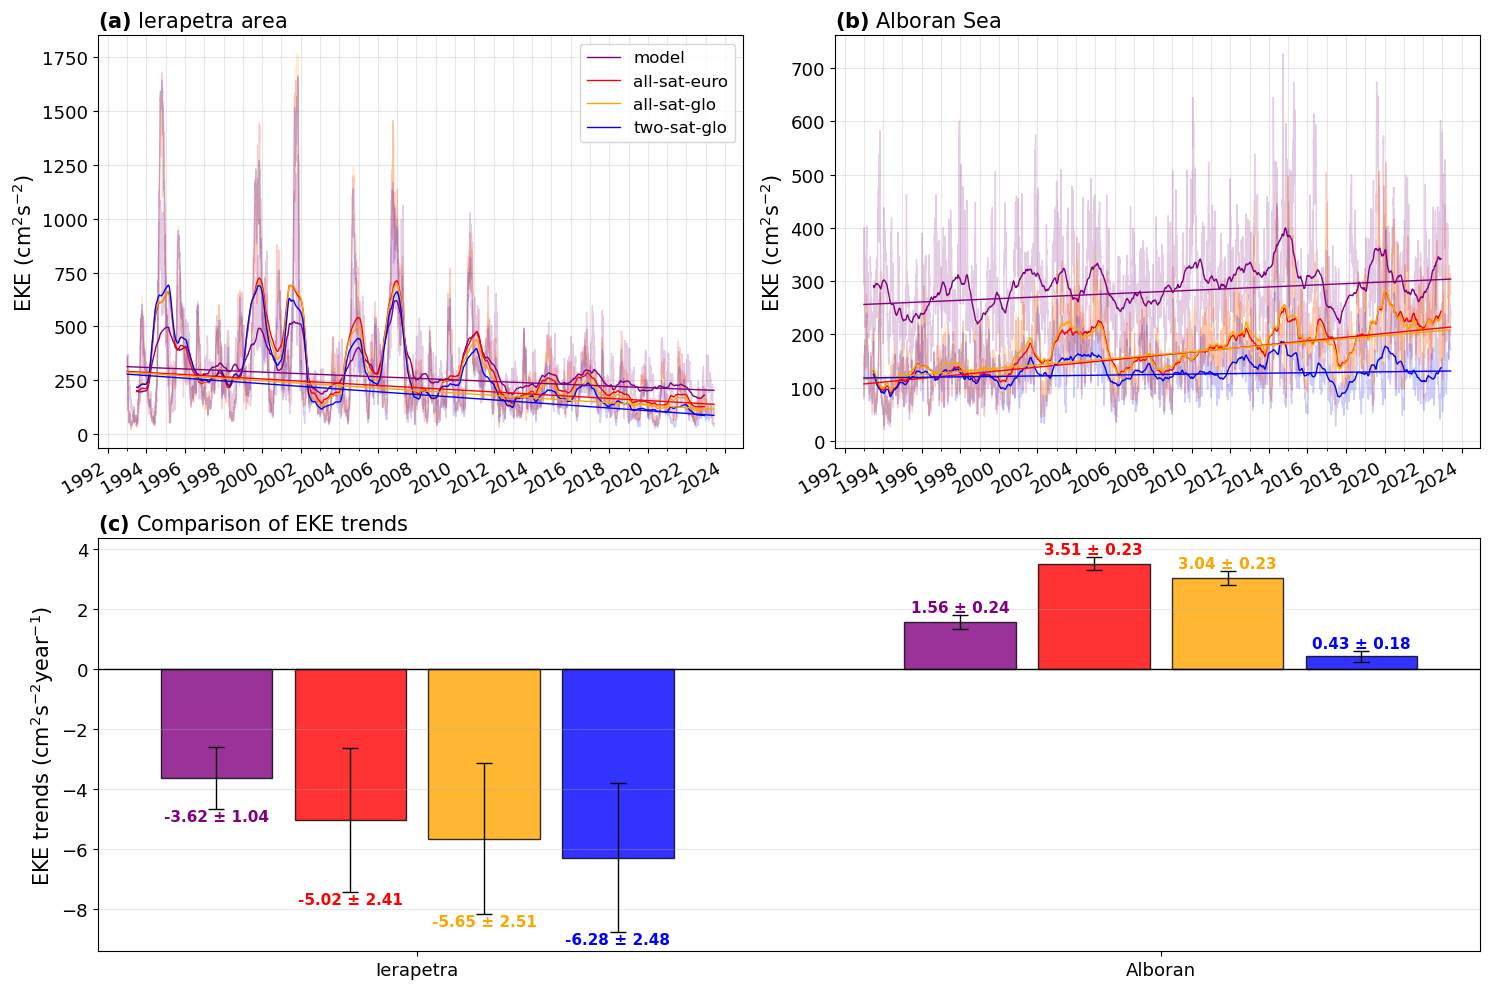

In [26]:
fig = plt.figure(figsize=(15, 10))

gs = gridspec.GridSpec(
    2, 2,
    height_ratios=[1, 1],
    width_ratios=[1, 1],
    figure=fig)

ax1 = fig.add_subplot(gs[0, 0])   # Ierapetra
ax2 = fig.add_subplot(gs[0, 1])   # Alboran
ax3 = fig.add_subplot(gs[1, :])   # Trends

# (a) IERAPETRA
ax1.plot(ds_meanekegsurf_iera.time, ds_meanekegsurf_iera, color='purple', lw=1, alpha=0.2)
ax1.plot(dsm_ierab.time, dsm_ierab.EKE, color='red', lw=1, alpha=0.2)
ax1.plot(dsa_ierab.time, dsa_ierab.EKE, color='orange', lw=1, alpha=0.2)
ax1.plot(dst_ierab.time, dst_ierab.EKE, color='blue', lw=1, alpha=0.2)
# Moyenne glissante 1 an
ax1.plot(ds_meanekegsurf_iera.time, ds_meanekegsurf_iera.rolling(time=365, center=True).mean(), color='purple', lw=1)
ax1.plot(dsm_ierab.time, dsm_ierab.EKE.rolling(time=365, center=True).mean(), color='red', lw=1, alpha=1)
ax1.plot(dsa_ierab.time, dsa_ierab.EKE.rolling(time=365, center=True).mean(), color='orange', lw=1, alpha=1)
ax1.plot(dst_ierab.time, dst_ierab.EKE.rolling(time=365, center=True).mean(), color='blue', lw=1, alpha=1)
# Tendance
time_r = ((ds_meanekegsurf_iera.time.values - ds_meanekegsurf_iera.time.values[0]) / np.timedelta64(1, 'D'))
ax1.plot(ds_meanekegsurf_iera.time, slierag / 365 * time_r + interierag,color='purple', linewidth=1, label='model'
        # label=(r'$\beta$ = ' + f'{slierag:.2f}' + r' $\pm$ ' + f'{incertierag:.2f}' + r' cm$^2$s$^{-2}$year$^{-1}$')
        )
time_r = ((dsm_ierab.time.values - dsm_ierab.time.values[0]) / np.timedelta64(1, 'D'))
ax1.plot(dsm_ierab.time, slm_ierab/365 * time_r + interm_ierab, color='red', linewidth=1, label='all-sat-euro')
time_r = ((dsa_ierab.time.values - dsa_ierab.time.values[0]) / np.timedelta64(1, 'D'))
ax1.plot(dsa_ierab.time, sla_ierab/365 * time_r + intera_ierab, color='orange', linewidth=1, label='all-sat-glo')
time_r = ((dst_ierab.time.values - dst_ierab.time.values[0]) / np.timedelta64(1, 'D'))
ax1.plot(dst_ierab.time, slt_ierab/365 * time_r + intert_ierab, color='blue', linewidth=1, label='two-sat-glo')

ax1.set_ylabel('EKE (cm$^2$s$^{-2}$)', fontsize=15)
ax1.set_title(r'$\bf{(a)}$ Ierapetra area', fontsize=15, loc='left')
ax1.legend(fontsize=12, loc='upper right')
ax1.grid(True, which='both', axis='both', alpha=0.3)
ax1.xaxis.set_major_locator(mdates.YearLocator(2))
ax1.xaxis.set_minor_locator(mdates.YearLocator(1))
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.setp(ax1.xaxis.get_majorticklabels(), rotation=30, ha='right')

# (b) ALBORAN
ax2.plot(ds_meanekegsurf_alb.time, ds_meanekegsurf_alb, color='purple', lw=1, alpha=0.2)
ax2.plot(dsm_alb.time, dsm_alb.EKE, color='red', lw=1, alpha=0.2)
ax2.plot(dsa_alb.time, dsa_alb.EKE, color='orange', lw=1, alpha=0.2)
ax2.plot(dst_alb.time, dst_alb.EKE, color='blue', lw=1, alpha=0.2)
# Moyenne glissante 1 an
ax2.plot(ds_meanekegsurf_alb.time, ds_meanekegsurf_alb.rolling(time=365, center=True).mean(), color='purple', lw=1)
ax2.plot(dsm_alb.time, dsm_alb.EKE.rolling(time=365, center=True).mean(), color='red', lw=1, alpha=1)
ax2.plot(dsa_alb.time, dsa_alb.EKE.rolling(time=365, center=True).mean(), color='orange', lw=1, alpha=1)
ax2.plot(dst_alb.time, dst_alb.EKE.rolling(time=365, center=True).mean(), color='blue', lw=1, alpha=1)
# Tendance
time_r = ((ds_meanekegsurf_alb.time.values - ds_meanekegsurf_alb.time.values[0]) / np.timedelta64(1, 'D'))
ax2.plot(ds_meanekegsurf_alb.time, slalbg / 365 * time_r + interalbg, color='purple', linewidth=1,
        # label=(r'$\beta$ = ' + f'{slalbg:.2f}' + r' $\pm$ ' + f'{incertalbg:.2f}' + r' cm$^2$s$^{-2}$year$^{-1}$')
        )
time_r = ((dsm_alb.time.values - dsm_alb.time.values[0]) / np.timedelta64(1, 'D'))
ax2.plot(dsm_alb.time, slm_alb/365 * time_r + interm_alb, color='red', linewidth=1)
time_r = ((dsa_alb.time.values - dsa_alb.time.values[0]) / np.timedelta64(1, 'D'))
ax2.plot(dsa_alb.time, sla_alb/365 * time_r + intera_alb, color='orange', linewidth=1)
time_r = ((dst_alb.time.values - dst_alb.time.values[0]) / np.timedelta64(1, 'D'))
ax2.plot(dst_alb.time, slt_alb/365 * time_r + intert_alb, color='blue', linewidth=1)

ax2.set_ylabel('EKE (cm$^2$s$^{-2}$)', fontsize=15)
ax2.set_title(r'$\bf{(b)}$ Alboran Sea', fontsize=15, loc='left')
# ax2.legend(fontsize=12, loc='upper left')
ax2.grid(True, which='both', axis='both', alpha=0.3)
ax2.xaxis.set_major_locator(mdates.YearLocator(2))
ax2.xaxis.set_minor_locator(mdates.YearLocator(1))
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.setp(ax2.xaxis.get_majorticklabels(), rotation=30, ha='right')

# (c) COMPARAISON DES TENDANCES
regions = ['Ierapetra', 'Alboran']

slopes_model = [slierag, slalbg]
slopes_m = [slm_ierab, slm_alb]
slopes_a = [sla_ierab, sla_alb]
slopes_t = [slt_ierab, slt_alb]

errors_model = [incertierag, incertalbg]
errors_m = [incertm_ierab, incertm_alb]
errors_a = [incerta_ierab, incerta_alb]
errors_t = [incertt_ierab, incertt_alb]

pvalues_model = [pierag, palbg]
pvalues_m = [pm_ierab, pm_alb]
pvalues_a = [pa_ierab, pa_alb]
pvalues_t = [pt_ierab, pt_alb]

xbar = np.arange(len(regions))
offset = 0.18
widthbar = 0.15

color_model = 'purple'
color_m = 'red'
color_a = 'orange'
color_t = 'blue'

all_slopes = [slopes_model, slopes_m, slopes_a, slopes_t]
all_errors = [errors_model, errors_m, errors_a, errors_t]
all_pvalues = [pvalues_model, pvalues_m, pvalues_a, pvalues_t]
all_colors = [color_model, color_m, color_a, color_t]
all_offsets = [-1.5 * offset, -0.5 * offset, 0.5 * offset, 1.5 * offset]

ax3.axhline(0, color='black', linewidth=1)
ax3.set_xticks(xbar)
ax3.set_xticklabels(regions, fontsize=15)
ax3.set_ylabel('EKE trends (cm$^2$s$^{-2}$year$^{-1}$)', fontsize=15)
ax3.set_title(r'$\bf{(c)}$ Comparison of EKE trends', fontsize=15, loc='left')
ax3.grid(True, axis='y', alpha=0.3)

for slopes, errors, pvalues, color, off in zip(all_slopes, all_errors, all_pvalues, all_colors, all_offsets):
    for i, (slope, error, pvalue) in enumerate(zip(slopes, errors, pvalues)):
        if pvalue > 0.05:
                    hatch = '//'
                    fontweight = 'normal'
                    fontstyle = 'italic'
        else:
                    hatch = None
                    fontweight = 'bold'
                    fontstyle = 'normal'
        ax3.bar(xbar[i] + off, slope, widthbar, color=color, alpha=0.8, edgecolor='black', hatch=hatch)
        ax3.errorbar(xbar[i] + off, slope, yerr=error, fmt='none', ecolor='black', elinewidth=1, capsize=6)
        if slope >= 0:
            y = slope + error
            va = 'bottom'
        else:
            y = slope - error
            va = 'top'
        ax3.text(xbar[i] + off, y, f'{slope:.2f} ± {error:.2f}',
            ha='center', va=va, fontsize=11, color=color, fontweight=fontweight, fontstyle=fontstyle)
# ax3.legend(fontsize=12, ncol=4, loc='upper center', bbox_to_anchor=(0.5, 1.02))


for ax in [ax1, ax2, ax3]:
    ax.tick_params(axis='both', labelsize=13)
plt.tight_layout()

plt.show()

In [27]:
sl_alb_modg = np.load('../../results/model_albvg_slpintns.npy', allow_pickle=True)
sl_alb_modg = sl_alb_modg.item()

sl_iera_modg = np.load('../../results/model_ieravg_slpintns.npy', allow_pickle=True)
sl_iera_modg = sl_iera_modg.item()

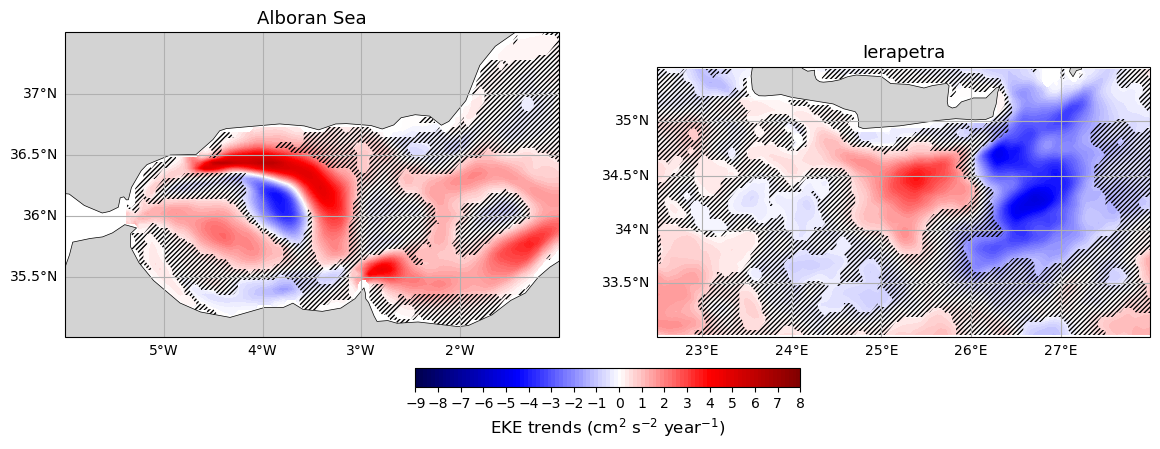

In [29]:
fig = plt.figure(figsize=(14, 5))

ax1 = fig.add_subplot(1, 2, 1, projection=ccrs.Mercator())
ax2 = fig.add_subplot(1, 2, 2, projection=ccrs.Mercator())

# Alboran
lon_min_alb = -6
lon_max_alb = -1
lat_min_alb = 35
lat_max_alb = 37.5

# Ierapetra
lon_min_iera = 22.5
lon_max_iera = 28
lat_min_iera = 33
lat_max_iera = 35.5

ax1.set_extent([lon_min_alb, lon_max_alb, lat_min_alb, lat_max_alb], crs=ccrs.PlateCarree())
ax2.set_extent([lon_min_iera, lon_max_iera, lat_min_iera, lat_max_iera], crs=ccrs.PlateCarree())

for ax in [ax1, ax2]:
    gl = ax.gridlines(draw_labels=True, dms=False, x_inline=False, y_inline=False)
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 10, 'color': 'black'}
    gl.ylabel_style = {'size': 10, 'color': 'black'}

lon_alb = uovo_alb.longitude.values
lat_alb = uovo_alb.latitude.values
lon_iera = uovo_iera.longitude.values
lat_iera = uovo_iera.latitude.values

vmin = -9
vmax = 8
norm = TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax)
levels = np.linspace(vmin, vmax, 100)

contour1 = ax1.contourf(lon_alb, lat_alb, sl_alb_modg['slope'] * 365, 
                        levels=levels, cmap='seismic', norm=norm, transform=ccrs.PlateCarree())
# Significance hatching
mask_alb_mod = np.where(sl_alb_modg['pvalue'] > 0.05, 1, np.nan)
ax1.contourf(lon_alb, lat_alb, mask_alb_mod, 
             levels=[0.99, 1.01], colors='none', hatches=['///////'], transform=ccrs.PlateCarree())

contour2 = ax2.contourf(lon_iera, lat_iera, sl_iera_modg['slope'] * 365,
                        levels=levels, cmap='seismic', norm=norm, transform=ccrs.PlateCarree())
# Significance hatching
mask_iera_mod = np.where(sl_iera_modg['pvalue'] > 0.05, 1, np.nan)
ax2.contourf(lon_iera, lat_iera, mask_iera_mod, levels=[0.99, 1.01],
             colors='none', hatches=['///////'], transform=ccrs.PlateCarree())

ccrs_land = cfeature.NaturalEarthFeature('physical', 'land',
    '50m', edgecolor='black', facecolor='lightgrey', linewidth=0.5)
for ax in [ax1, ax2]:
    ax.add_feature(ccrs_land)

ax1.set_title('Alboran Sea', fontsize=13)
ax2.set_title('Ierapetra', fontsize=13)
cbar = fig.colorbar(contour1, ax=[ax1, ax2], orientation='horizontal', pad=0.08, fraction=0.05)
cbar.set_label(r'EKE trends (cm$^2$ s$^{-2}$ year$^{-1}$)', fontsize=12)
cbar.ax.tick_params(labelsize=10)
cbar.set_ticks(np.arange(vmin, vmax + 1, 1))

plt.show()

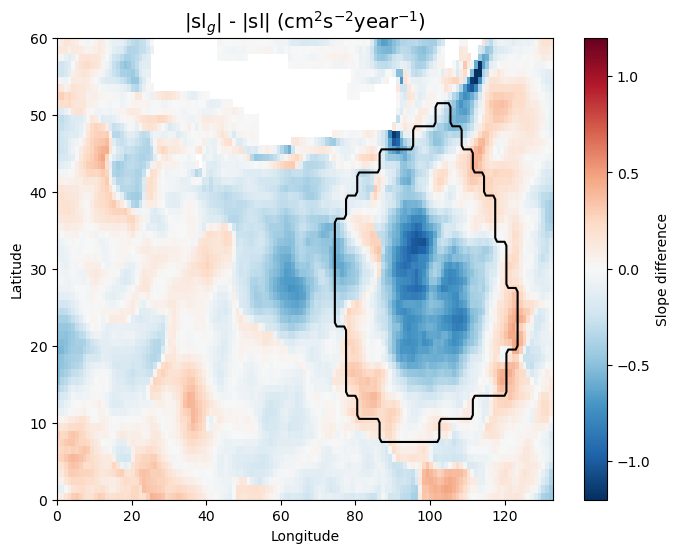

In [33]:
#Slope difference
plt.figure(figsize=(8, 6))

im = plt.pcolor(np.abs(sl_iera_modg['slope']*365) - np.abs(sl_iera_mod['slope']*365), cmap='RdBu_r', vmin=-1.2, vmax=1.2)

plt.colorbar(im, label='Slope difference')
plt.contour(mask_uovo, levels=[0.5], colors='black', linewidths=1.5)
plt.title(r'|sl$_g$| - |sl| (cm$^2$s$^{-2}$year$^{-1}$)', fontsize=14)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

## Tests 1994

In [71]:
ssh_sat = xr.open_dataset('/media/hargous/MyPassport/Med_Global_EKE/data/med_allsat_L4_008_068/vDT2021/1994/dt_med_allsat_phy_l4_1994.nc')

In [72]:
# Moyenne climatologique 1993-2012
zos_mean_932012 = ssh_iera.zos.sel(
    time=slice("1993-01-01", "2012-12-31")
).mean(dim="time")

# Anomalie de SSH
zos_anom = ssh_iera.zos - zos_mean_932012

# Moyenne de l'anomalie sur 2015
zos_anom_1994 = zos_anom.sel(
    time=slice("1994-07-01", "1994-12-31")
).mean(dim="time")

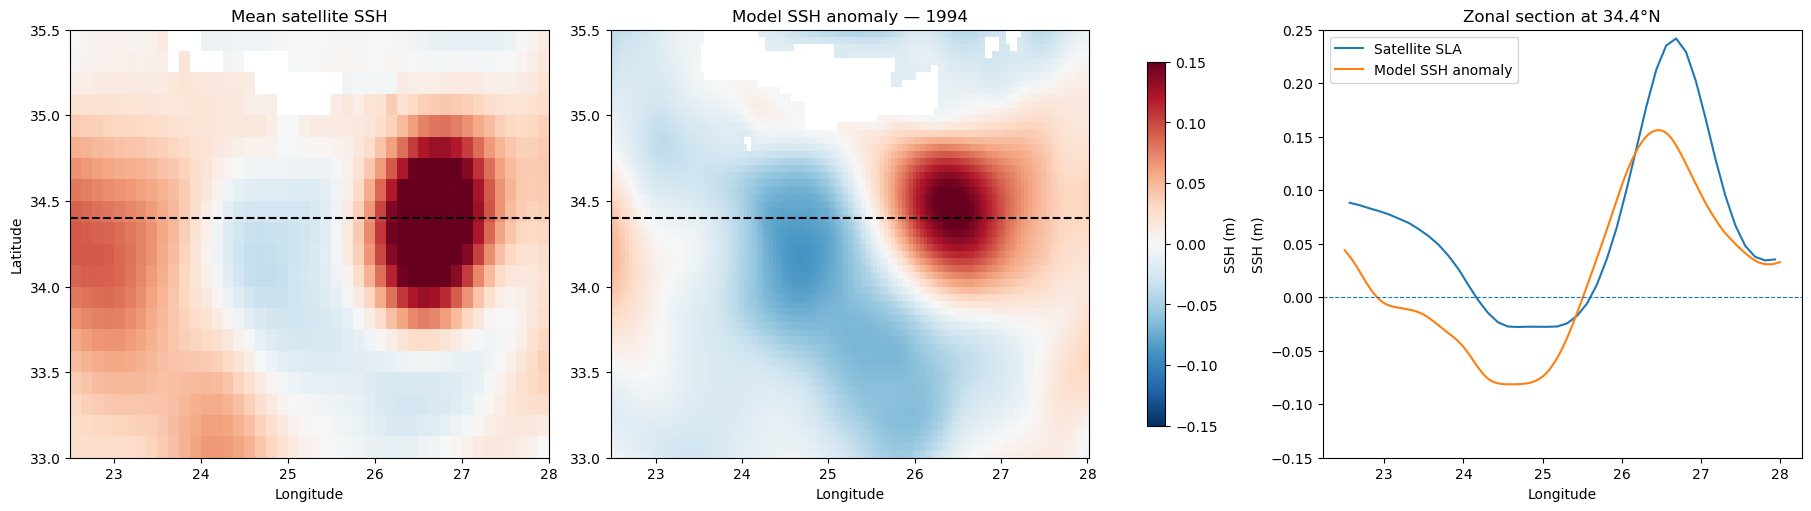

In [73]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5),
    constrained_layout=True
)

ssh_mean = ssh_sat.sla.sel(time=slice("1994-07-01", "1994-12-31")).mean(dim="time").sel(longitude=slice(22.5, 28), latitude=slice(33, 35.5))
im1 = ssh_mean.plot(ax=axes[0], vmin=-0.15, vmax=0.15, cmap="RdBu_r", add_colorbar=False)
axes[0].axhline(34.4, color="black", linestyle="--", linewidth=1.5)
axes[0].set_title("Mean satellite SSH")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")

im2 = zos_anom_1994.plot(ax=axes[1], vmin=-0.15, vmax=0.15, cmap="RdBu_r", add_colorbar=False)
axes[1].axhline(34.4, color="black", linestyle="--", linewidth=1.5)
axes[1].set_title("Model SSH anomaly — 1994")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("")

# Satellite
sla_section = ssh_sat.sla.sel(time=slice("1994-07-01", "1994-12-31")).mean(dim="time").sel(
    latitude=34.4,method="nearest"
).sel(longitude=slice(22.5, 28))

# Modèle
zos_section = zos_anom_1994.sel(
    latitude=34.4, method="nearest"
).sel(longitude=slice(22.5, 28))

axes[2].plot(sla_section.longitude, sla_section, label="Satellite SLA")
axes[2].plot(zos_section.longitude, zos_section, label="Model SSH anomaly")
axes[2].axhline(0, linestyle="--", linewidth=0.8)
axes[2].set_ylim(-0.15, 0.25)
axes[2].set_xlabel("Longitude")
axes[2].set_ylabel("SSH (m)")
axes[2].set_title("Zonal section at 34.4°N")
axes[2].legend()

cbar = fig.colorbar(im1, ax=axes[:2], orientation="vertical", shrink=0.85, label="SSH (m)")

plt.show()

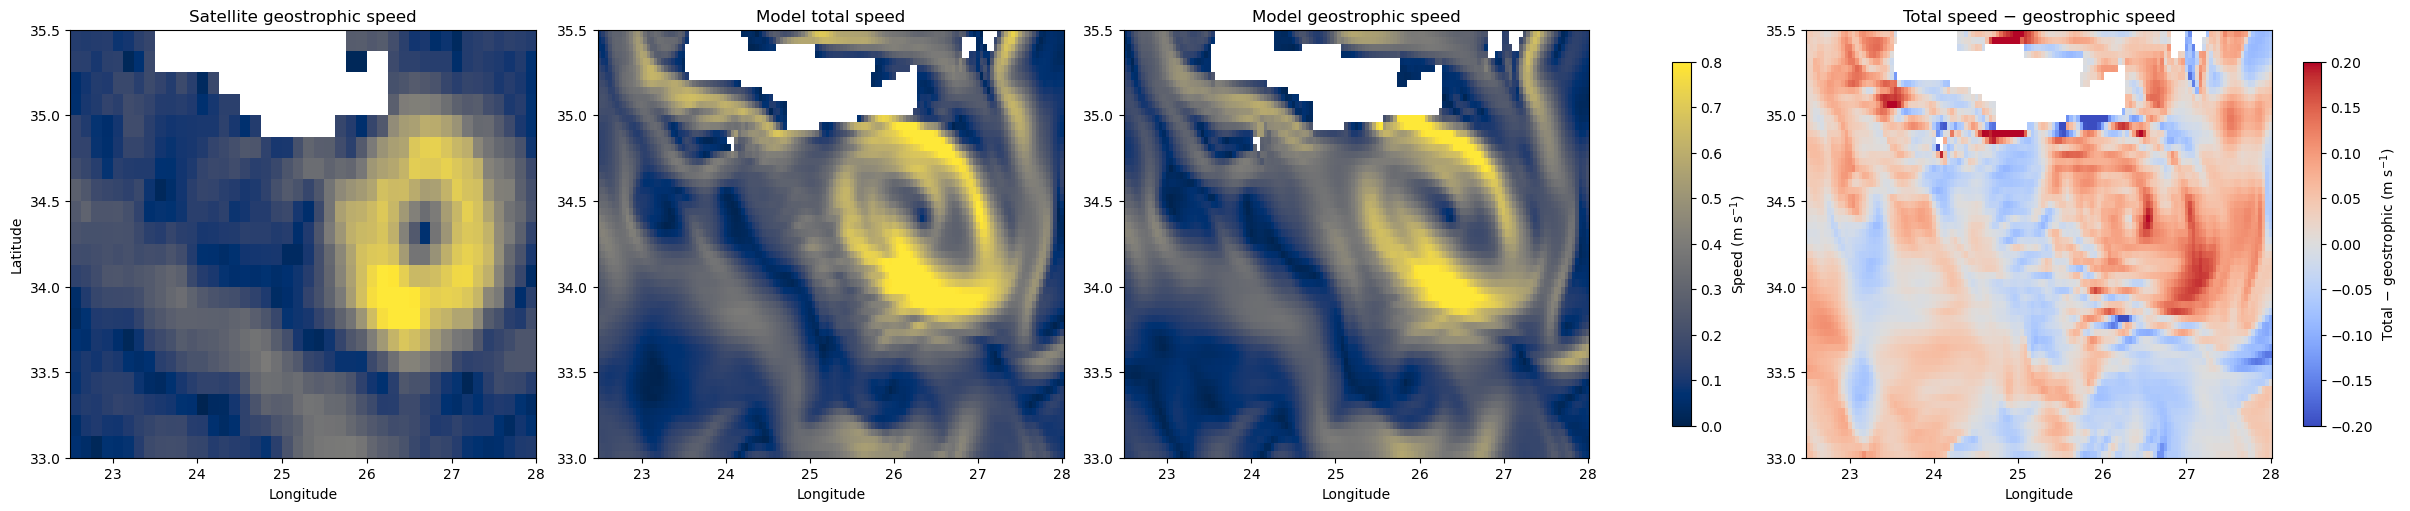

In [80]:
fig, axes = plt.subplots(
    1, 4,
    figsize=(24, 5),
    constrained_layout=True
)

# ============================================================
# 1. Satellite : vitesse géostrophique
# ============================================================

ugos_iera_1994 = ssh_sat.ugos.sel(
    time=slice("1994-07-01", "1994-12-31"),
    longitude=slice(22.5, 28),
    latitude=slice(33, 35.5)
).sel(time="1994-10-01", method="nearest")

vgos_iera_1994 = ssh_sat.vgos.sel(
    time=slice("1994-07-01", "1994-12-31"),
    longitude=slice(22.5, 28),
    latitude=slice(33, 35.5)
).sel(time="1994-10-01", method="nearest")

speed_sat = np.sqrt(
    ugos_iera_1994**2 +
    vgos_iera_1994**2
)

speed_sat.plot(
    ax=axes[0],
    vmin=0,
    vmax=0.8,
    cmap="cividis",
    add_colorbar=False
)

axes[0].set_title("Satellite geostrophic speed")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")


# ============================================================
# 2. Modèle : vitesse totale
# ============================================================

uovo_iera_1994 = (
    uovo_iera
    .isel(depth=0)
    .sel(time=slice("1994-07-01", "1994-12-31"))
    .sel(time="1994-10-01", method="nearest")
)

speed_model_total = np.sqrt(
    uovo_iera_1994.uo**2 +
    uovo_iera_1994.vo**2
)

speed_model_total.plot(
    ax=axes[1],
    vmin=0,
    vmax=0.8,
    cmap="cividis",
    add_colorbar=False
)

axes[1].set_title("Model total speed")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("")


# ============================================================
# 3. Modèle : vitesse géostrophique
# ============================================================

ds_geo_iera_1994 = (
    ds_geo_iera
    .sel(time=slice("1994-07-01", "1994-12-31"))
    .sel(time="1994-10-01", method="nearest")
)

speed_model_geo = np.sqrt(
    ds_geo_iera_1994.ug**2 +
    ds_geo_iera_1994.vg**2
)

speed_model_geo.plot(
    ax=axes[2],
    vmin=0,
    vmax=0.8,
    cmap="cividis",
    add_colorbar=False
)

axes[2].set_title("Model geostrophic speed")
axes[2].set_xlabel("Longitude")
axes[2].set_ylabel("")


# ============================================================
# 4. Différence : vitesse totale - vitesse géostrophique
# ============================================================

speed_difference = (
    speed_model_total - speed_model_geo
)

speed_difference.plot(
    ax=axes[3],
    vmin=-0.2,
    vmax=0.2,
    cmap="coolwarm",
    add_colorbar=False
)

axes[3].set_title(
    "Total speed − geostrophic speed"
)

axes[3].set_xlabel("Longitude")
axes[3].set_ylabel("")


# ============================================================
# Colorbar commune pour les 3 vitesses
# ============================================================

cbar_speed = fig.colorbar(
    axes[0].collections[0],
    ax=axes[:3],
    label="Speed (m s$^{-1}$)",
    shrink=0.85
)


# ============================================================
# Colorbar pour la différence
# ============================================================

cbar_diff = fig.colorbar(
    axes[3].collections[0],
    ax=axes[3],
    label="Total − geostrophic (m s$^{-1}$)",
    shrink=0.85
)

plt.show()

In [101]:
ssh_sat = ssh_sat.sel(longitude=slice(-6, 37), latitude=slice(30, 47))

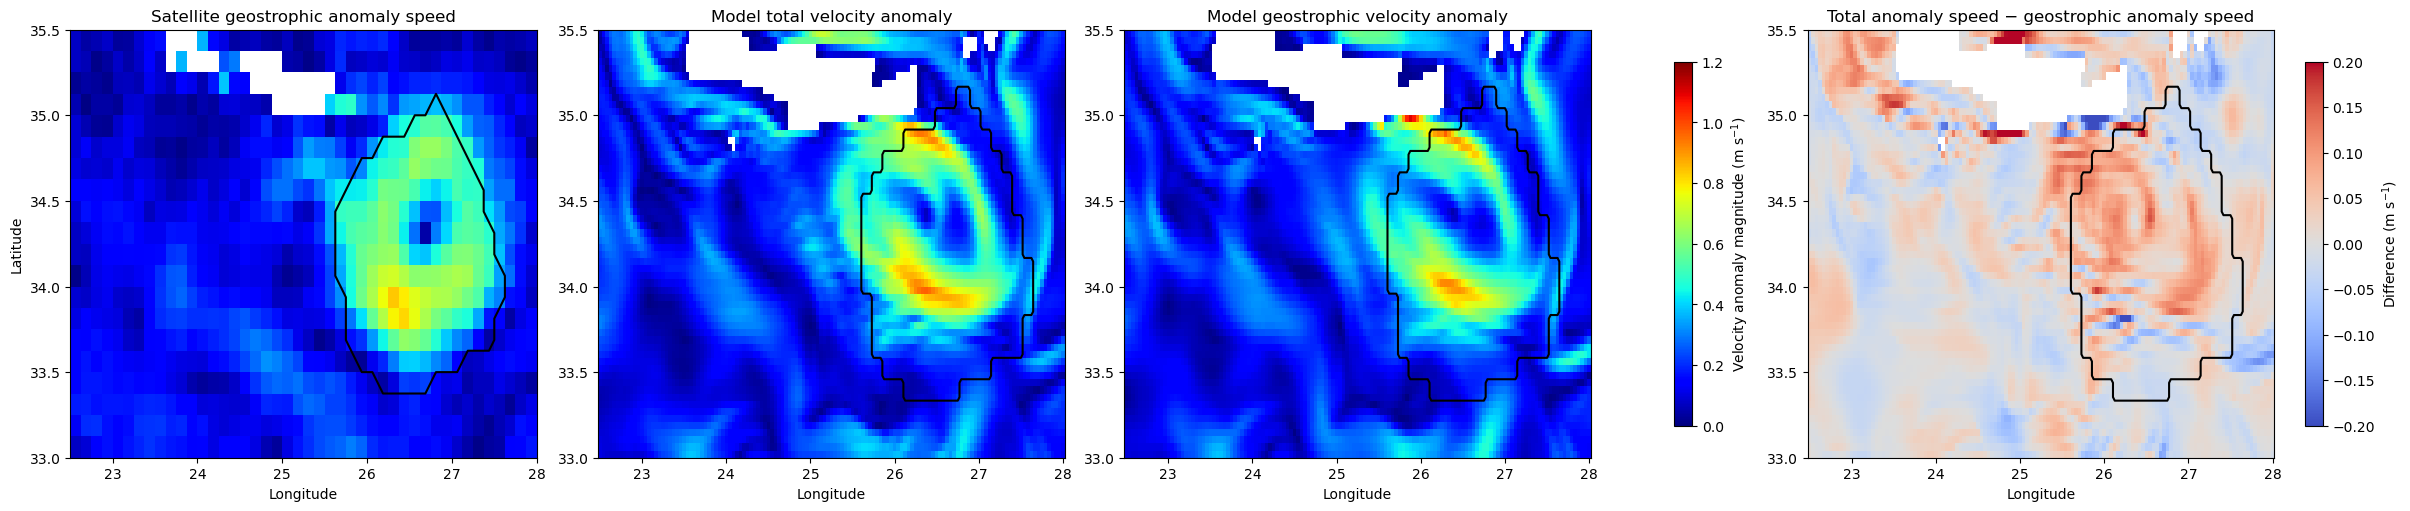

In [104]:
fig, axes = plt.subplots(
    1, 4,
    figsize=(24, 5),
    constrained_layout=True
)

# ============================================================
# DATE D'ANALYSE
# ============================================================

date = "1994-10-01"


# ============================================================
# PERIODE DE REFERENCE MODELE
# ============================================================

clim_start = "1993-01-01"
clim_end   = "2012-12-31"


# ============================================================
# 1. SATELLITE : VITESSE GEOSTROPHIQUE ANOMALE
# ============================================================

ugosa_iera = ssh_sat.ugosa.sel(
    time=slice("1994-07-01", "1994-12-31"),
    longitude=slice(22.5, 28),
    latitude=slice(33, 35.5)
).sel(
    time=date,
    method="nearest"
)

vgosa_iera = ssh_sat.vgosa.sel(
    time=slice("1994-07-01", "1994-12-31"),
    longitude=slice(22.5, 28),
    latitude=slice(33, 35.5)
).sel(
    time=date,
    method="nearest"
)

# vitesse à partir des anomalies de composantes
speed_sat_anom = np.sqrt(
    ugosa_iera**2 +
    vgosa_iera**2
)

speed_sat_anom.plot(
    ax=axes[0],
    vmin=0,
    vmax=1.2,
    cmap="jet",
    add_colorbar=False
)
axes[0].contour(
    ssh_sat.longitude,
    ssh_sat.latitude,
    mask,
    levels=[0.5],
    colors="black",
    linewidths=1.5
)
axes[0].set_title(
    "Satellite geostrophic anomaly speed"
)

axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")


# ============================================================
# 2. MODELE : ANOMALIE DE VITESSE TOTALE
# ============================================================

# ------------------------------------------------------------
# Climatologie 1993-2012
# ------------------------------------------------------------

uovo_clim = (
    uovo_iera
    .isel(depth=0)
    .sel(
        time=slice(
            clim_start,
            clim_end
        )
    )
    .mean(dim="time")
)

# ------------------------------------------------------------
# Champ du 1er octobre 1994
# ------------------------------------------------------------

uovo_date = (
    uovo_iera
    .isel(depth=0)
    .sel(
        time=date,
        method="nearest"
    )
)

# ------------------------------------------------------------
# Anomalies de composantes
# ------------------------------------------------------------

uo_anom = (
    uovo_date.uo -
    uovo_clim.uo
)

vo_anom = (
    uovo_date.vo -
    uovo_clim.vo
)

# ------------------------------------------------------------
# Norme de l'anomalie de vitesse
# ------------------------------------------------------------

speed_model_total_anom = np.sqrt(
    uo_anom**2 +
    vo_anom**2
)

speed_model_total_anom.plot(
    ax=axes[1],
    vmin=0,
    vmax=1.2,
    cmap="jet",
    add_colorbar=False
)
axes[1].contour(
    uovo_iera.longitude,
    uovo_iera.latitude,
    mask_uovo,
    levels=[0.5],
    colors="black",
    linewidths=1.5
)
axes[1].set_title(
    "Model total velocity anomaly"
)

axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("")


# ============================================================
# 3. MODELE : ANOMALIE DE VITESSE GEOSTROPHIQUE
# ============================================================

# ------------------------------------------------------------
# Climatologie géostrophique 1993-2012
# ------------------------------------------------------------

geo_clim = (
    ds_geo_iera
    .sel(
        time=slice(
            clim_start,
            clim_end
        )
    )
    .mean(dim="time")
)

# ------------------------------------------------------------
# Champ géostrophique du 1er octobre 1994
# ------------------------------------------------------------

geo_date = (
    ds_geo_iera
    .sel(
        time=date,
        method="nearest"
    )
)

# ------------------------------------------------------------
# Anomalies des composantes géostrophiques
# ------------------------------------------------------------

ug_anom = (
    geo_date.ug -
    geo_clim.ug
)

vg_anom = (
    geo_date.vg -
    geo_clim.vg
)

# ------------------------------------------------------------
# Norme de l'anomalie géostrophique
# ------------------------------------------------------------

speed_model_geo_anom = np.sqrt(
    ug_anom**2 +
    vg_anom**2
)

speed_model_geo_anom.plot(
    ax=axes[2],
    vmin=0,
    vmax=1.2,
    cmap="jet",
    add_colorbar=False
)
axes[2].contour(
    uovo_iera.longitude,
    uovo_iera.latitude,
    mask_uovo,
    levels=[0.5],
    colors="black",
    linewidths=1.5
)
axes[2].set_title(
    "Model geostrophic velocity anomaly"
)

axes[2].set_xlabel("Longitude")
axes[2].set_ylabel("")


# ============================================================
# 4. DIFFERENCE ENTRE ANOMALIE TOTALE ET GEOSTROPHIQUE
# ============================================================

speed_difference_anom = (
    speed_model_total_anom -
    speed_model_geo_anom
)

speed_difference_anom.plot(
    ax=axes[3],
    vmin=-0.2,
    vmax=0.2,
    cmap="coolwarm",
    add_colorbar=False
)
axes[3].contour(
    uovo_iera.longitude,
    uovo_iera.latitude,
    mask_uovo,
    levels=[0.5],
    colors="black",
    linewidths=1.5
)
axes[3].set_title(
    "Total anomaly speed − geostrophic anomaly speed"
)

axes[3].set_xlabel("Longitude")
axes[3].set_ylabel("")


# ============================================================
# COLORBAR : ANOMALIES DE VITESSE
# ============================================================

cbar_speed = fig.colorbar(
    axes[0].collections[0],
    ax=axes[:3],
    label="Velocity anomaly magnitude (m s$^{-1}$)",
    shrink=0.85
)


# ============================================================
# COLORBAR : DIFFERENCE
# ============================================================

cbar_diff = fig.colorbar(
    axes[3].collections[0],
    ax=axes[3],
    label="Difference (m s$^{-1}$)",
    shrink=0.85
)


plt.show()

In [105]:
# ============================================================
# Date
# ============================================================
date = "1994-10-01"

# ============================================================
# 1. SATELLITE
# ============================================================

sat_date = ssh_sat.sel(time=date, method="nearest")

u_sat_anom = sat_date["ugosa"]
v_sat_anom = sat_date["vgosa"]

eke_u_sat = 0.5 * u_sat_anom**2
eke_v_sat = 0.5 * v_sat_anom**2
eke_sat = eke_u_sat + eke_v_sat


# ============================================================
# 2. MODEL TOTAL
# ============================================================

model_date = (
    uovo_iera
    .isel(depth=0)
    .sel(time=date, method="nearest")
)

uovo_clim = (
    uovo_iera
    .isel(depth=0)
    .sel(time=slice("1993-01-01", "2012-12-31"))
    .mean("time")
)

uo_anom = model_date["uo"] - uovo_clim["uo"]
vo_anom = model_date["vo"] - uovo_clim["vo"]

eke_u_total = 0.5 * uo_anom**2
eke_v_total = 0.5 * vo_anom**2
eke_total = eke_u_total + eke_v_total


# ============================================================
# 3. MODEL GEOSTROPHIC
# ============================================================

geo_date = (
    ds_geo_iera
    .sel(time=date, method="nearest")
)

geo_clim = (
    ds_geo_iera
    .sel(time=slice("1993-01-01", "2012-12-31"))
    .mean("time")
)

ug_anom = geo_date["ug"] - geo_clim["ug"]
vg_anom = geo_date["vg"] - geo_clim["vg"]

eke_u_geo = 0.5 * ug_anom**2
eke_v_geo = 0.5 * vg_anom**2
eke_geo = eke_u_geo + eke_v_geo

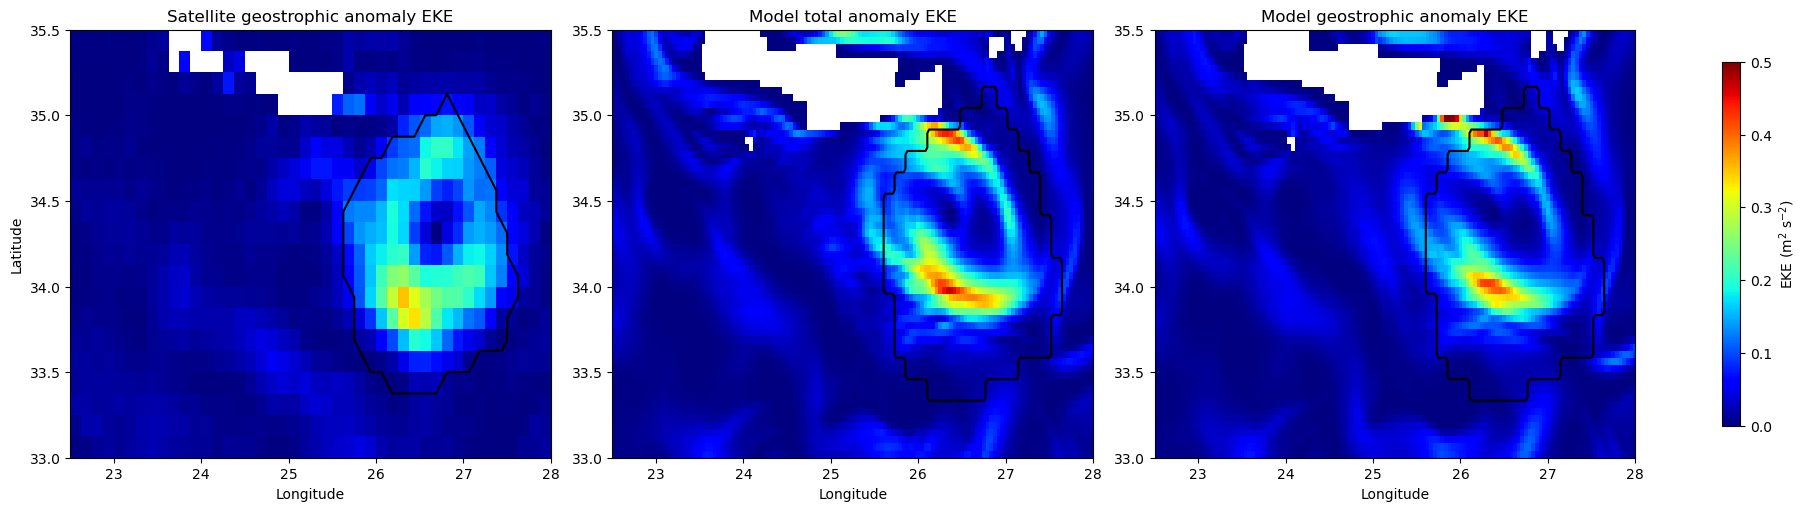

In [120]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5),
    constrained_layout=True
)

# ============================================================
# DATE D'ANALYSE
# ============================================================

date = "1994-10-01"


# ============================================================
# PERIODE DE REFERENCE MODELE
# ============================================================

clim_start = "1993-01-01"
clim_end   = "2012-12-31"


# ============================================================
# 1. SATELLITE : EKE ANOMALE
# ============================================================

ugosa_iera = ssh_sat.ugosa.sel(
    time=slice("1994-07-01", "1994-12-31"),
    # longitude=slice(22.5, 28),
    # latitude=slice(33, 35.5)
).sel(
    time=date,
    method="nearest"
)

vgosa_iera = ssh_sat.vgosa.sel(
    time=slice("1994-07-01", "1994-12-31"),
    # longitude=slice(22.5, 28),
    # latitude=slice(33, 35.5)
).sel(
    time=date,
    method="nearest"
)

# ------------------------------------------------------------
# EKE
# ------------------------------------------------------------

eke_sat = 0.5 * (
    ugosa_iera**2 +
    vgosa_iera**2
)

eke_sat.plot(
    ax=axes[0],
    vmin=0,
    vmax=0.5,
    cmap="jet",
    add_colorbar=False
)

axes[0].contour(
    ssh_sat.longitude,
    ssh_sat.latitude,
    mask,
    levels=[0.5],
    colors="black",
    linewidths=1.5
)

axes[0].set_title(
    "Satellite geostrophic anomaly EKE"
)

axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")


# ============================================================
# 2. MODELE : EKE ANOMALE TOTALE
# ============================================================

# ------------------------------------------------------------
# Climatologie 1993-2012
# ------------------------------------------------------------

uovo_clim = (
    uovo_iera
    .isel(depth=0)
    .sel(
        time=slice(
            clim_start,
            clim_end
        )
    )
    .mean(dim="time")
)

# ------------------------------------------------------------
# Champ du 1er octobre 1994
# ------------------------------------------------------------

uovo_date = (
    uovo_iera
    .isel(depth=0)
    .sel(
        time=date,
        method="nearest"
    )
)

# ------------------------------------------------------------
# Anomalies de composantes
# ------------------------------------------------------------

uo_anom = (
    uovo_date.uo -
    uovo_clim.uo
)

vo_anom = (
    uovo_date.vo -
    uovo_clim.vo
)

# ------------------------------------------------------------
# EKE totale
# ------------------------------------------------------------

eke_model_total = 0.5 * (
    uo_anom**2 +
    vo_anom**2
)

eke_model_total.plot(
    ax=axes[1],
    vmin=0,
    vmax=0.5,
    cmap="jet",
    add_colorbar=False
)

axes[1].contour(
    uovo_iera.longitude,
    uovo_iera.latitude,
    mask_uovo,
    levels=[0.5],
    colors="black",
    linewidths=1.5
)

axes[1].set_title(
    "Model total anomaly EKE"
)

axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("")


# ============================================================
# 3. MODELE : EKE ANOMALE GEOSTROPHIQUE
# ============================================================

# ------------------------------------------------------------
# Climatologie géostrophique 1993-2012
# ------------------------------------------------------------

geo_clim = (
    ds_geo_iera
    .sel(
        time=slice(
            clim_start,
            clim_end
        )
    )
    .mean(dim="time")
)

# ------------------------------------------------------------
# Champ géostrophique du 1er octobre 1994
# ------------------------------------------------------------

geo_date = (
    ds_geo_iera
    .sel(
        time=date,
        method="nearest"
    )
)

# ------------------------------------------------------------
# Anomalies des composantes
# ------------------------------------------------------------

ug_anom = (
    geo_date.ug -
    geo_clim.ug
)

vg_anom = (
    geo_date.vg -
    geo_clim.vg
)

# ------------------------------------------------------------
# EKE géostrophique
# ------------------------------------------------------------

eke_model_geo = 0.5 * (
    ug_anom**2 +
    vg_anom**2
)

eke_model_geo.plot(
    ax=axes[2],
    vmin=0,
    vmax=0.5,
    cmap="jet",
    add_colorbar=False
)

axes[2].contour(
    uovo_iera.longitude,
    uovo_iera.latitude,
    mask_uovo,
    levels=[0.5],
    colors="black",
    linewidths=1.5
)

axes[2].set_title(
    "Model geostrophic anomaly EKE"
)

axes[2].set_xlabel("Longitude")
axes[2].set_ylabel("")


# ============================================================
# LIMITES IDENTIQUES
# ============================================================

for ax in axes:
    ax.set_xlim(22.5, 28)
    ax.set_ylim(33, 35.5)


# ============================================================
# COLORBAR UNIQUE
# ============================================================

cbar = fig.colorbar(
    axes[0].collections[0],
    ax=axes,
    label="EKE (m$^2$ s$^{-2}$)",
    shrink=0.85
)

plt.show()

# Vgeo avec 2 points

In [87]:
# ============================================================
# 1. Dérivée numérique avec 2 points
# ============================================================

def derivative_2point(field, axis, h):
    """
    Calcule une dérivée numérique avec :

    - points intérieurs :
        df/dx = (f[i+1] - f[i-1]) / (2h)

    - première frontière :
        df/dx = (f[1] - f[0]) / h

    - dernière frontière :
        df/dx = (f[-1] - f[-2]) / h

    Parameters
    ----------
    field : ndarray
        Champ sur lequel calculer la dérivée.
    axis : int
        Axe selon lequel calculer la dérivée.
    h : float
        Pas de grille.

    Returns
    -------
    derivative : ndarray
        Dérivée du champ.
    """

    field = np.asarray(field, dtype=np.float64)

    n = field.shape[axis]

    if n < 3:
        raise ValueError(
            "Il faut au moins 3 points sur l'axe considéré."
        )

    derivative = np.empty_like(field, dtype=np.float64)

    # --------------------------------------------------------
    # Points intérieurs : différence centrée
    # --------------------------------------------------------

    sl_center = [slice(None)] * field.ndim
    sl_center[axis] = slice(1, n - 1)

    sl_forward = [slice(None)] * field.ndim
    sl_forward[axis] = slice(2, n)

    sl_backward = [slice(None)] * field.ndim
    sl_backward[axis] = slice(0, n - 2)

    derivative[tuple(sl_center)] = (
        field[tuple(sl_forward)]
        - field[tuple(sl_backward)]
    ) / (2.0 * h)

    # --------------------------------------------------------
    # Premier point : différence avant
    # --------------------------------------------------------

    sl0 = [slice(None)] * field.ndim
    sl0[axis] = 0

    sl1 = [slice(None)] * field.ndim
    sl1[axis] = 1

    derivative[tuple(sl0)] = (
        field[tuple(sl1)]
        - field[tuple(sl0)]
    ) / h

    # --------------------------------------------------------
    # Dernier point : différence arrière
    # --------------------------------------------------------

    sl_last = [slice(None)] * field.ndim
    sl_last[axis] = n - 1

    sl_before = [slice(None)] * field.ndim
    sl_before[axis] = n - 2

    derivative[tuple(sl_last)] = (
        field[tuple(sl_last)]
        - field[tuple(sl_before)]
    ) / h

    return derivative


# ============================================================
# 2. Calcul des vitesses géostrophiques à partir de SSH
# ============================================================

def compute_geostrophic_velocity(
    zos,
    latitude,
    longitude,
    g=9.81,
    Omega=7.292115e-5,
    R=6371000.0,
    time_chunk=200
):
    """
    Calcule les vitesses géostrophiques à partir de la SSH.

    Équations :

        ug = -g/f * dSSH/dy

        vg =  g/f * dSSH/dx

    avec :

        dy = R dphi

        dx = R cos(phi) dlambda

        f = 2 Omega sin(phi)

    Parameters
    ----------
    zos : xarray.DataArray
        SSH avec dimensions (time, latitude, longitude).

    latitude : array
        Latitudes en degrés.

    longitude : array
        Longitudes en degrés.

    g : float
        Accélération gravitationnelle.

    Omega : float
        Vitesse de rotation de la Terre.

    R : float
        Rayon terrestre.

    time_chunk : int
        Nombre de dates traitées simultanément.

    Returns
    -------
    ug : xarray.DataArray
        Vitesse zonale géostrophique.

    vg : xarray.DataArray
        Vitesse méridienne géostrophique.
    """

    # --------------------------------------------------------
    # Vérification des dimensions
    # --------------------------------------------------------

    if zos.dims != ("time", "latitude", "longitude"):
        raise ValueError(
            f"Dimensions inattendues : {zos.dims}. "
            "Les dimensions doivent être "
            "('time', 'latitude', 'longitude')."
        )

    lat = np.asarray(latitude, dtype=np.float64)
    lon = np.asarray(longitude, dtype=np.float64)

    # --------------------------------------------------------
    # Pas de grille
    #
    # On utilise la médiane car les coordonnées sont en float32
    # et peuvent avoir de très petites différences numériques.
    # --------------------------------------------------------

    dlat = np.diff(lat)
    dlon = np.diff(lon)

    dphi = np.deg2rad(np.median(dlat))
    dlambda = np.deg2rad(np.median(dlon))

    # --------------------------------------------------------
    # Vérification que la grille est bien quasi régulière
    # --------------------------------------------------------

    if not np.allclose(
        dlat,
        np.median(dlat),
        rtol=1e-4,
        atol=1e-7
    ):
        raise ValueError(
            "La grille latitude est trop irrégulière."
        )

    if not np.allclose(
        dlon,
        np.median(dlon),
        rtol=1e-4,
        atol=1e-7
    ):
        raise ValueError(
            "La grille longitude est trop irrégulière."
        )

    # --------------------------------------------------------
    # Latitude en radians
    # --------------------------------------------------------

    phi = np.deg2rad(lat)

    # Coriolis
    f = 2.0 * Omega * np.sin(phi)

    # --------------------------------------------------------
    # Préparation des coordonnées
    # --------------------------------------------------------

    ug = np.empty(
        zos.shape,
        dtype=np.float32
    )

    vg = np.empty(
        zos.shape,
        dtype=np.float32
    )

    # --------------------------------------------------------
    # Traitement par blocs temporels
    # --------------------------------------------------------

    for i0 in range(0, zos.sizes["time"], time_chunk):

        i1 = min(
            i0 + time_chunk,
            zos.sizes["time"]
        )

        print(
            f"Calcul géostrophique : "
            f"{i0} - {i1} / {zos.sizes['time']}"
        )

        # ----------------------------------------------------
        # Lecture du bloc
        # ----------------------------------------------------

        ssh = zos.isel(
            time=slice(i0, i1)
        ).values

        ssh = np.asarray(
            ssh,
            dtype=np.float64
        )

        # ----------------------------------------------------
        # dSSH / dphi
        #
        # axe 1 = latitude
        # ----------------------------------------------------

        dssh_dphi = derivative_2point(
            ssh,
            axis=1,
            h=dphi
        )

        # ----------------------------------------------------
        # dSSH / dlambda
        #
        # axe 2 = longitude
        # ----------------------------------------------------

        dssh_dlambda = derivative_2point(
            ssh,
            axis=2,
            h=dlambda
        )

        # ----------------------------------------------------
        # Conversion en dérivées physiques
        #
        # dSSH/dy = dSSH/dphi / R
        #
        # dSSH/dx = dSSH/dlambda /
        #           (R cos(phi))
        # ----------------------------------------------------

        dssh_dy = dssh_dphi / R

        cosphi = np.cos(phi)[None, :, None]

        dssh_dx = (
            dssh_dlambda
            / (R * cosphi)
        )

        # ----------------------------------------------------
        # Vitesses géostrophiques
        #
        # ug = -g/f * dSSH/dy
        #
        # vg =  g/f * dSSH/dx
        # ----------------------------------------------------

        f_3d = f[None, :, None]

        ug_block = (
            -g
            / f_3d
            * dssh_dy
        )

        vg_block = (
            g
            / f_3d
            * dssh_dx
        )

        # ----------------------------------------------------
        # Stockage
        # ----------------------------------------------------

        ug[i0:i1, :, :] = ug_block.astype(
            np.float32
        )

        vg[i0:i1, :, :] = vg_block.astype(
            np.float32
        )

    # ========================================================
    # Création des DataArrays xarray
    # ========================================================

    ug = xr.DataArray(
        ug,
        dims=zos.dims,
        coords=zos.coords,
        name="ug"
    )

    vg = xr.DataArray(
        vg,
        dims=zos.dims,
        coords=zos.coords,
        name="vg"
    )

    # --------------------------------------------------------
    # Attributs
    # --------------------------------------------------------

    ug.attrs = {
        "long_name": "geostrophic zonal velocity",
        "units": "m s-1",
        "description": (
            "Geostrophic velocity calculated from "
            "sea surface height"
        )
    }

    vg.attrs = {
        "long_name": "geostrophic meridional velocity",
        "units": "m s-1",
        "description": (
            "Geostrophic velocity calculated from "
            "sea surface height"
        )
    }

    return ug, vg


# ============================================================
# 3. ALBORAN
# ============================================================

zos = ssh_alb["zos"]

ug_alb, vg_alb = compute_geostrophic_velocity(
    zos,
    latitude=ssh_alb["latitude"].values,
    longitude=ssh_alb["longitude"].values,
    time_chunk=200
)

ds_geo_alb = xr.Dataset(
    {
        "ug": ug_alb,
        "vg": vg_alb
    }
)


# ============================================================
# 4. IERAPETRA
# ============================================================

zos = ssh_iera["zos"]

ug_iera, vg_iera = compute_geostrophic_velocity(
    zos,
    latitude=ssh_iera["latitude"].values,
    longitude=ssh_iera["longitude"].values,
    time_chunk=200
)

ds_geo_iera = xr.Dataset(
    {
        "ug": ug_iera,
        "vg": vg_iera
    }
)

Calcul géostrophique : 0 - 200 / 12296
Calcul géostrophique : 200 - 400 / 12296
Calcul géostrophique : 400 - 600 / 12296
Calcul géostrophique : 600 - 800 / 12296
Calcul géostrophique : 800 - 1000 / 12296
Calcul géostrophique : 1000 - 1200 / 12296
Calcul géostrophique : 1200 - 1400 / 12296
Calcul géostrophique : 1400 - 1600 / 12296
Calcul géostrophique : 1600 - 1800 / 12296
Calcul géostrophique : 1800 - 2000 / 12296
Calcul géostrophique : 2000 - 2200 / 12296
Calcul géostrophique : 2200 - 2400 / 12296
Calcul géostrophique : 2400 - 2600 / 12296
Calcul géostrophique : 2600 - 2800 / 12296
Calcul géostrophique : 2800 - 3000 / 12296
Calcul géostrophique : 3000 - 3200 / 12296
Calcul géostrophique : 3200 - 3400 / 12296
Calcul géostrophique : 3400 - 3600 / 12296
Calcul géostrophique : 3600 - 3800 / 12296
Calcul géostrophique : 3800 - 4000 / 12296
Calcul géostrophique : 4000 - 4200 / 12296
Calcul géostrophique : 4200 - 4400 / 12296
Calcul géostrophique : 4400 - 4600 / 12296
Calcul géostrophique :

In [88]:
ug_surf = ds_geo_iera.ug.sel(time=slice(None, '2023-06-07'))
vg_surf = ds_geo_iera.vg.sel(time=slice(None, '2023-06-07'))
uga_surf = ug_surf - ug_surf.mean(dim='time')
vga_surf = vg_surf - vg_surf.mean(dim='time')
ekeg_surf_iera = 0.5 * (uga_surf**2 + vga_surf**2)*10000

ug_surf = ds_geo_alb.ug.sel(time=slice(None, '2023-06-07'))
vg_surf = ds_geo_alb.vg.sel(time=slice(None, '2023-06-07'))
uga_surf = ug_surf - ug_surf.mean(dim='time')
vga_surf = vg_surf - vg_surf.mean(dim='time')
ekeg_surf_alb = 0.5 * (uga_surf**2 + vga_surf**2)*10000

In [89]:
area = utils.get_area_haversine(ekeg_surf_iera['latitude'], ekeg_surf_iera['longitude'])
da_area = xr.Dataset(coords={'latitude': ekeg_surf_iera.latitude, 'longitude': ekeg_surf_iera.longitude})
da_area['area'] = (('latitude', 'longitude'), area)
area = da_area['area'].where(ekeg_surf_iera.notnull().any(dim='time'))
area_sum = area.sum(['latitude', 'longitude']).compute()
area_rat = area/area_sum
ds_meanekegsurf_iera = (ekeg_surf_iera * area_rat).sum(['latitude', 'longitude']).compute()

area = utils.get_area_haversine(ekeg_surf_alb['latitude'], ekeg_surf_alb['longitude'])
da_area = xr.Dataset(coords={'latitude': ekeg_surf_alb.latitude, 'longitude': ekeg_surf_alb.longitude})
da_area['area'] = (('latitude', 'longitude'), area)
area = da_area['area'].where(ekeg_surf_alb.notnull().any(dim='time'))
area_sum = area.sum(['latitude', 'longitude']).compute()
area_rat = area/area_sum
ds_meanekegsurf_alb = (ekeg_surf_alb * area_rat).sum(['latitude', 'longitude']).compute()


In [90]:
slierag, pierag, nnsierag, interierag = pmk_test(ds_meanekegsurf_iera)*np.array((365,1,1,1))
incertierag = std_mktrend(ds_meanekegsurf_iera, slierag, interierag, len(ds_meanekegsurf_iera)/nnsierag)

slalbg, palbg, nnsalbg, interalbg = pmk_test(ds_meanekegsurf_alb)*np.array((365,1,1,1))
incertalbg = std_mktrend(ds_meanekegsurf_alb, slalbg, interalbg, len(ds_meanekegsurf_alb)/nnsalbg)

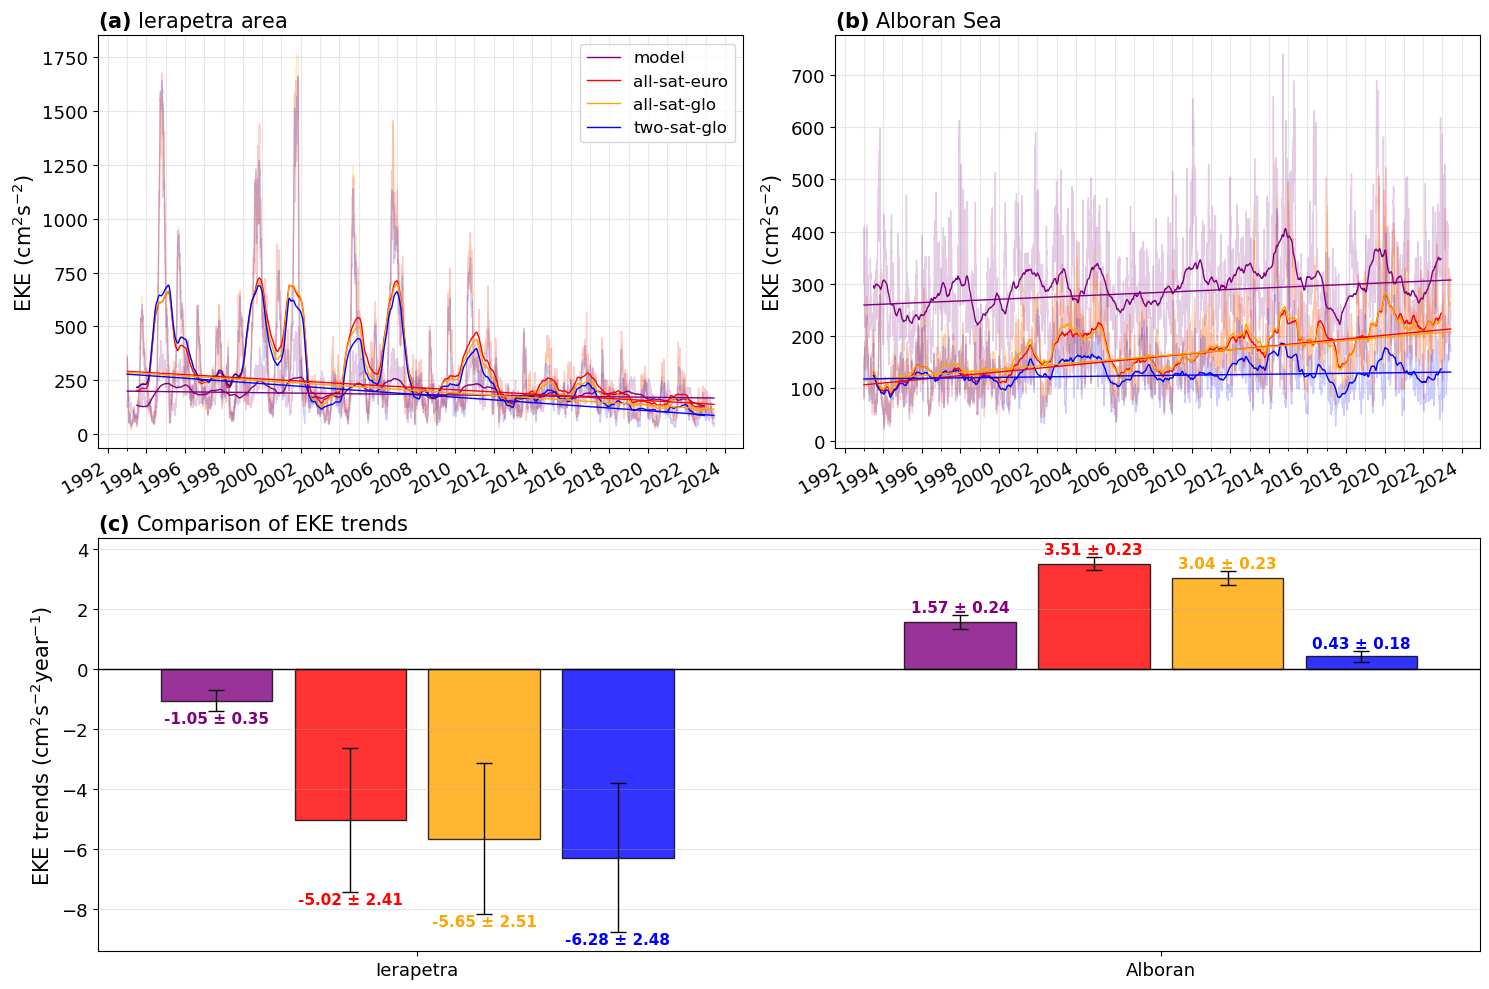

In [91]:
fig = plt.figure(figsize=(15, 10))

gs = gridspec.GridSpec(
    2, 2,
    height_ratios=[1, 1],
    width_ratios=[1, 1],
    figure=fig
)

ax1 = fig.add_subplot(gs[0, 0])   # Ierapetra
ax2 = fig.add_subplot(gs[0, 1])   # Alboran
ax3 = fig.add_subplot(gs[1, :])   # Trends


# ============================================================
# (a) IERAPETRA
# ============================================================

ax1.plot(ds_meanekegsurf_iera.time, ds_meanekegsurf_iera, color='purple', lw=1, alpha=0.2)
ax1.plot(dsm_ierab.time, dsm_ierab.EKE, color='red', lw=1, alpha=0.2)
ax1.plot(dsa_ierab.time, dsa_ierab.EKE, color='orange', lw=1, alpha=0.2)
ax1.plot(dst_ierab.time, dst_ierab.EKE, color='blue', lw=1, alpha=0.2)
# Moyenne glissante 1 an
ax1.plot(ds_meanekegsurf_iera.time, ds_meanekegsurf_iera.rolling(time=365, center=True).mean(), color='purple', lw=1)
ax1.plot(dsm_ierab.time, dsm_ierab.EKE.rolling(time=365, center=True).mean(), color='red', lw=1, alpha=1)
ax1.plot(dsa_ierab.time, dsa_ierab.EKE.rolling(time=365, center=True).mean(), color='orange', lw=1, alpha=1)
ax1.plot(dst_ierab.time, dst_ierab.EKE.rolling(time=365, center=True).mean(), color='blue', lw=1, alpha=1)
# Tendance
time_r = ((ds_meanekegsurf_iera.time.values - ds_meanekegsurf_iera.time.values[0]) / np.timedelta64(1, 'D'))
ax1.plot(ds_meanekegsurf_iera.time, slierag / 365 * time_r + interierag,color='purple', linewidth=1, label='model'
        # label=(r'$\beta$ = ' + f'{slierag:.2f}' + r' $\pm$ ' + f'{incertierag:.2f}' + r' cm$^2$s$^{-2}$year$^{-1}$')
        )
time_r = ((dsm_ierab.time.values - dsm_ierab.time.values[0]) / np.timedelta64(1, 'D'))
ax1.plot(dsm_ierab.time, slm_ierab/365 * time_r + interm_ierab, color='red', linewidth=1, label='all-sat-euro')
time_r = ((dsa_ierab.time.values - dsa_ierab.time.values[0]) / np.timedelta64(1, 'D'))
ax1.plot(dsa_ierab.time, sla_ierab/365 * time_r + intera_ierab, color='orange', linewidth=1, label='all-sat-glo')
time_r = ((dst_ierab.time.values - dst_ierab.time.values[0]) / np.timedelta64(1, 'D'))
ax1.plot(dst_ierab.time, slt_ierab/365 * time_r + intert_ierab, color='blue', linewidth=1, label='two-sat-glo')

ax1.set_ylabel('EKE (cm$^2$s$^{-2}$)', fontsize=15)

ax1.set_title(r'$\bf{(a)}$ Ierapetra area', fontsize=15, loc='left')

ax1.legend(fontsize=12, loc='upper right')

ax1.grid(True, which='both', axis='both', alpha=0.3)

ax1.xaxis.set_major_locator(mdates.YearLocator(2))
ax1.xaxis.set_minor_locator(mdates.YearLocator(1))
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.setp(ax1.xaxis.get_majorticklabels(), rotation=30, ha='right')


# ============================================================
# (b) ALBORAN
# ============================================================

ax2.plot(ds_meanekegsurf_alb.time, ds_meanekegsurf_alb, color='purple', lw=1, alpha=0.2)
ax2.plot(dsm_alb.time, dsm_alb.EKE, color='red', lw=1, alpha=0.2)
ax2.plot(dsa_alb.time, dsa_alb.EKE, color='orange', lw=1, alpha=0.2)
ax2.plot(dst_alb.time, dst_alb.EKE, color='blue', lw=1, alpha=0.2)
# Moyenne glissante 1 an
ax2.plot(ds_meanekegsurf_alb.time, ds_meanekegsurf_alb.rolling(time=365, center=True).mean(), color='purple', lw=1)
ax2.plot(dsm_alb.time, dsm_alb.EKE.rolling(time=365, center=True).mean(), color='red', lw=1, alpha=1)
ax2.plot(dsa_alb.time, dsa_alb.EKE.rolling(time=365, center=True).mean(), color='orange', lw=1, alpha=1)
ax2.plot(dst_alb.time, dst_alb.EKE.rolling(time=365, center=True).mean(), color='blue', lw=1, alpha=1)
# Tendance
time_r = ((ds_meanekegsurf_alb.time.values - ds_meanekegsurf_alb.time.values[0]) / np.timedelta64(1, 'D'))
ax2.plot(ds_meanekegsurf_alb.time, slalbg / 365 * time_r + interalbg, color='purple', linewidth=1,
        # label=(r'$\beta$ = ' + f'{slalbg:.2f}' + r' $\pm$ ' + f'{incertalbg:.2f}' + r' cm$^2$s$^{-2}$year$^{-1}$')
        )
time_r = ((dsm_alb.time.values - dsm_alb.time.values[0]) / np.timedelta64(1, 'D'))
ax2.plot(dsm_alb.time, slm_alb/365 * time_r + interm_alb, color='red', linewidth=1)
time_r = ((dsa_alb.time.values - dsa_alb.time.values[0]) / np.timedelta64(1, 'D'))
ax2.plot(dsa_alb.time, sla_alb/365 * time_r + intera_alb, color='orange', linewidth=1)
time_r = ((dst_alb.time.values - dst_alb.time.values[0]) / np.timedelta64(1, 'D'))
ax2.plot(dst_alb.time, slt_alb/365 * time_r + intert_alb, color='blue', linewidth=1)

ax2.set_ylabel('EKE (cm$^2$s$^{-2}$)', fontsize=15)

ax2.set_title(r'$\bf{(b)}$ Alboran Sea', fontsize=15, loc='left')

# ax2.legend(fontsize=12, loc='upper left')

ax2.grid(True, which='both', axis='both', alpha=0.3)

ax2.xaxis.set_major_locator(mdates.YearLocator(2))
ax2.xaxis.set_minor_locator(mdates.YearLocator(1))
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.setp(ax2.xaxis.get_majorticklabels(), rotation=30, ha='right')


# ============================================================
# (c) COMPARAISON DES TENDANCES
# ============================================================

regions = ['Ierapetra', 'Alboran']

slopes_model = [slierag, slalbg]
slopes_m = [slm_ierab, slm_alb]
slopes_a = [sla_ierab, sla_alb]
slopes_t = [slt_ierab, slt_alb]

errors_model = [incertierag, incertalbg]
errors_m = [incertm_ierab, incertm_alb]
errors_a = [incerta_ierab, incerta_alb]
errors_t = [incertt_ierab, incertt_alb]

pvalues_model = [pierag, palbg]
pvalues_m = [pm_ierab, pm_alb]
pvalues_a = [pa_ierab, pa_alb]
pvalues_t = [pt_ierab, pt_alb]

xbar = np.arange(len(regions))
offset = 0.18
widthbar = 0.15

color_model = 'purple'
color_m = 'red'
color_a = 'orange'
color_t = 'blue'

all_slopes = [slopes_model, slopes_m, slopes_a, slopes_t]
all_errors = [errors_model, errors_m, errors_a, errors_t]
all_pvalues = [pvalues_model, pvalues_m, pvalues_a, pvalues_t]
all_colors = [color_model, color_m, color_a, color_t]
all_offsets = [-1.5 * offset, -0.5 * offset, 0.5 * offset, 1.5 * offset]

ax3.axhline(0, color='black', linewidth=1)

ax3.set_xticks(xbar)
ax3.set_xticklabels(regions, fontsize=15)

ax3.set_ylabel('EKE trends (cm$^2$s$^{-2}$year$^{-1}$)', fontsize=15)

ax3.set_title(r'$\bf{(c)}$ Comparison of EKE trends', fontsize=15, loc='left')

ax3.grid(True, axis='y', alpha=0.3)

for slopes, errors, pvalues, color, off in zip(all_slopes, all_errors, all_pvalues, all_colors, all_offsets):
    for i, (slope, error, pvalue) in enumerate(zip(slopes, errors, pvalues)):
        if pvalue > 0.05:
                    hatch = '//'
                    fontweight = 'normal'
                    fontstyle = 'italic'
        else:
                    hatch = None
                    fontweight = 'bold'
                    fontstyle = 'normal'
        ax3.bar(xbar[i] + off, slope, widthbar, color=color, alpha=0.8, edgecolor='black', hatch=hatch)
        ax3.errorbar(xbar[i] + off, slope, yerr=error, fmt='none', ecolor='black', elinewidth=1, capsize=6)

        if slope >= 0:
            y = slope + error
            va = 'bottom'
        else:
            y = slope - error
            va = 'top'
        ax3.text(xbar[i] + off, y, f'{slope:.2f} ± {error:.2f}',
            ha='center', va=va, fontsize=11, color=color, fontweight=fontweight, fontstyle=fontstyle)

# ax3.legend(fontsize=12, ncol=4, loc='upper center', bbox_to_anchor=(0.5, 1.02))

# ============================================================
# STYLE
# ============================================================

for ax in [ax1, ax2, ax3]:
    ax.tick_params(axis='both', labelsize=13)

plt.tight_layout()

plt.show()

# Test

In [52]:
# EKE normalisée
eke_alb_norm = (ds_meanekegsurf_alb - ds_meanekegsurf_alb.std(dim="time")) / ds_meanekegsurf_alb.mean(dim="time")
eke_m_alb_norm = (dsm_alb.EKE - dsm_alb.EKE.std(dim="time")) / dsm_alb.EKE.mean(dim="time")
eke_a_alb_norm = (dsa_alb.EKE - dsa_alb.EKE.std(dim="time")) / dsa_alb.EKE.mean(dim="time")
eke_t_alb_norm = (dst_alb.EKE - dst_alb.EKE.std(dim="time")) / dst_alb.EKE.mean(dim="time")

slalbvg_norm, palbvg_norm, nnsalbvg_norm, interalbvg_norm = pmk_test(eke_alb_norm)*np.array((365,1,1,1))
incertalbvg_norm = std_mktrend(eke_alb_norm, slalbvg_norm, interalbvg_norm, len(eke_alb_norm)/nnsalbvg_norm)
slalbm_norm, palbm_norm, nnsalbm_norm, interalbm_norm = pmk_test(eke_m_alb_norm)*np.array((365,1,1,1))
incertalbm_norm = std_mktrend(eke_m_alb_norm, slalbm_norm, interalbm_norm, len(eke_m_alb_norm)/nnsalbm_norm)
slalba_norm, palba_norm, nnsalba_norm, interalba_norm = pmk_test(eke_a_alb_norm)*np.array((365,1,1,1))
incertalba_norm = std_mktrend(eke_a_alb_norm, slalba_norm, interalba_norm, len(eke_a_alb_norm)/nnsalba_norm)
slalbt_norm, palbt_norm, nnsalbt_norm, interalbt_norm = pmk_test(eke_t_alb_norm)*np.array((365,1,1,1))
incertalbt_norm = std_mktrend(eke_t_alb_norm, slalbt_norm, interalbt_norm, len(eke_t_alb_norm)/nnsalbt_norm)

In [53]:
slalbvg_norm, slalbm_norm, slalba_norm, slalbt_norm

(np.float64(0.005345820606832622),
 np.float64(0.0204403318702841),
 np.float64(0.017457006312959236),
 np.float64(0.0032957063450174185))

In [54]:
# EKE normalisée
eke_iera_norm = (ds_meanekegsurf_iera - ds_meanekegsurf_iera.std(dim="time")) / ds_meanekegsurf_iera.mean(dim="time")
eke_m_ierab_norm = (dsm_ierab.EKE - dsm_ierab.EKE.std(dim="time")) / dsm_ierab.EKE.mean(dim="time")
eke_a_ierab_norm = (dsa_ierab.EKE - dsa_ierab.EKE.std(dim="time")) / dsa_ierab.EKE.mean(dim="time")
eke_t_ierab_norm = (dst_ierab.EKE - dst_ierab.EKE.std(dim="time")) / dst_ierab.EKE.mean(dim="time")

slieravg_norm, pieravg_norm, nnsieravg_norm, interieravg_norm = pmk_test(eke_iera_norm)*np.array((365,1,1,1))
incertieravg_norm = std_mktrend(eke_iera_norm, slieravg_norm, interieravg_norm, len(eke_iera_norm)/nnsieravg_norm)
slierabm_norm, pierabm_norm, nnsierabm_norm, interierabm_norm = pmk_test(eke_m_ierab_norm)*np.array((365,1,1,1))
incertierabm_norm = std_mktrend(eke_m_ierab_norm, slierabm_norm, interierabm_norm, len(eke_m_ierab_norm)/nnsierabm_norm)
slieraba_norm, pieraba_norm, nnsieraba_norm, interieraba_norm = pmk_test(eke_a_ierab_norm)*np.array((365,1,1,1))
incertieraba_norm = std_mktrend(eke_a_ierab_norm, slieraba_norm, interieraba_norm, len(eke_a_ierab_norm)/nnsieraba_norm)
slierabt_norm, pierabt_norm, nnsierabt_norm, interierabt_norm = pmk_test(eke_t_ierab_norm)*np.array((365,1,1,1))
incertierabt_norm = std_mktrend(eke_t_ierab_norm, slierabt_norm, interierabt_norm, len(eke_t_ierab_norm)/nnsierabt_norm)

In [55]:
slieravg_norm, slierabm_norm, slieraba_norm, slierabt_norm

(np.float64(-0.01204621442797053),
 np.float64(-0.01673482505055642),
 np.float64(-0.019571690118245305),
 np.float64(-0.023365945742927004))

In [57]:
depths = [50, 100, 200, 500, 1000]

In [58]:
uovo_sel = uovo_alb.sel(depth=depths, method="nearest")

In [60]:
period = slice("1993-01-01", "2012-12-31")

u_clim = uovo_sel.uo.sel(time=period).mean("time")
v_clim = uovo_sel.vo.sel(time=period).mean("time")

u_anom = uovo_sel.uo - u_clim
v_anom = uovo_sel.vo - v_clim

eke_total = 0.5 * (u_anom**2 + v_anom**2)

In [64]:
depths = [50, 100, 200, 500, 1000]

theta_sel = thetao_alb.sel(depth=depths, method="nearest")
so_sel    = so_alb.sel(depth=depths, method="nearest")